# German day-ahead price forecast

**Contents**

- Objective
- 1\. Data
    - 1.1 Raw files
    - 1.2 Parse and join
- 2\. Split
- 3\. Exploration
    - 3.1 Dataset structure
    - 3.2 The yearly mean price rose almost 8 times, from 30 to 235 EUR/MWh
    - 3.3 The decision only depends on the shape of the day
    - 3.4 Residual load sets the shape, and its slope moves with the price level
    - 3.5 Price memory
    - 3.6 Neighbouring zones
    - 3.7 Negative prices
    - 3.8 Calendar
    - 3.9 Collinearity among the forecasts
    - 3.10 Which shift simple rules would pick
    - 3.11 What the exploration found
- 4\. Cleaning and features
    - 4.1 Cleaning
    - 4.2 Hypotheses and features
- 5\. Modelling
    - 5.1 Comparing the models
    - 5.2 Choosing feature groups
    - 5.3 Tuning both methods
- 6\. Diagnostics
- 7\. Evaluation
    - 7.1 Test: 2025
    - 7.2 What the test shows
    - 7.3 Reserve: 2026, a bonus score
- 8\. In practice
    - 8.1 Savings through 2025
    - 8.2 One day of the decision
- Conclusion

## Objective

A German manufacturer runs one 8-hour shift a day and buys 500 MWh for it, 62.5 MW in each hour. At 11:55 on D-1, five minutes before the day-ahead auction closes, it picks when tomorrow's shift starts, anywhere from 00:00 to 16:00, to make electricity plus staff premiums as cheap as possible. This notebook builds the price forecast it picks from. The full case is in `project.md`.

| | |
|---|---|
| Target | `price_da`, the DE-LU day-ahead clearing price in EUR/MWh, one row per delivery hour |
| Predict or explain | Predict. The model is judged on held-out error, and its coefficients are a by-product |
| Forecast moment | 11:55 German time on D-1, 12 to 36 hours ahead. Nothing published after that may be a feature |
| The decision | `shift cost = mean(price_h + premium_h)` over the 8 shift hours, in EUR/MWh. `premium_h` is 10 EUR/MWh (625 EUR of extra staff cost an hour, spread over 62.5 MWh) from 22:00 to 06:00 and in every weekend hour, otherwise 0 |
| What an error costs | Only which shift wins changes the purchase. The size of the price differences matters, not only their order: a cheap hour is not worth it if it pulls expensive neighbours into the shift. A forecast 20 EUR/MWh too high in every hour still costs nothing |
| Metrics | MAE and RMSE for the course, MASE against same-hour-yesterday so years at different price levels compare. The decision metric is the cost of the chosen shift against a standard 06:00 to 14:00 shift and against perfect hindsight |
| Simplifications | Shifts stay within one day, though a real shift can cross midnight. The weekend premium applies to every hour, so it adds to the cost but never changes which weekend shift wins. Night and weekend premiums do not stack, though in practice a weekend night usually earns both |


Load the libraries and the three fetch functions, and set the plot and table display defaults.


In [1]:
import numpy as np
import polars as pl
from plotnine import (
    aes,
    annotate,
    element_text,
    facet_wrap,
    geom_col,
    geom_hline,
    geom_line,
    geom_point,
    geom_ribbon,
    geom_text,
    geom_tile,
    ggplot,
    labs,
    scale_fill_gradient,
    scale_x_continuous,
    theme,
    theme_minimal,
    theme_set,
)
from xgboost import XGBRegressor

from lib.data_schemas import CombinedDataSchema
from lib.decision import SHIFT_MW, best_shift, premium
from lib.evaluation import cross_validate, evaluate, summarise_folds
from lib.fetching import fetch_de_prices, fetch_forecasts, fetch_neighbor_prices
from lib.modeling import AsinhTarget, LassoThenXGB, df_to_np, lear_forecast
from lib.splitting import make_folds

# legend on top: a legend on the right sits past the pane edge when the plot is wide
theme_set(theme_minimal() + theme(figure_size=(10, 4.5), legend_position="top"))
# a kernel has no terminal, so polars would squeeze every table into ~100 characters
_ = (
    pl.Config.set_tbl_rows(30)
    .set_tbl_cols(-1)  # show every column
    .set_tbl_width_chars(1000)  # wide tables use the pane instead of wrapping
    .set_fmt_str_lengths(60)
    .set_float_precision(3)
)

## 1. Data

### 1.1 Raw files

The three fetch functions in `lib/fetching.py` each return one raw dataset, read from its parquet file in `data/`. `refresh=True` pulls it again from the Energy-Charts API. The files hold what the API served, untouched.


Load the three raw datasets from `data/`, pulling from the API only if a file is missing.


In [2]:
prices_raw = fetch_de_prices()
forecasts_raw = fetch_forecasts()
neighbors_raw = fetch_neighbor_prices()

### 1.2 Parse and join

Mechanical fixes only, the same for every file:

1. Every file is averaged to UTC hours. Prices go quarter-hourly on 2025-10-01 and the forecasts are quarter-hourly throughout, so the mean puts all three on one grid. It also fills Switzerland, which stays hourly and leaves three of every four quarter-hours empty.
2. The join starts from the price table, so every row has a target.
3. Calendar columns are in German local time, because demand follows the local clock.
4. `fc_residual` is load minus solar and wind, as defined in `project.md`.
5. The result is validated against the data model in `lib/data_schemas.py`. Read that file for what the table holds.


Average every file to UTC hours.


In [3]:
def to_hourly(raw: pl.DataFrame) -> pl.DataFrame:
    return (
        raw.sort("utc_timestamp")
        .group_by_dynamic("utc_timestamp", every="1h")
        .agg(pl.all().mean())
    )


prices = to_hourly(prices_raw)
forecasts = to_hourly(forecasts_raw)
neighbors = to_hourly(neighbors_raw)

Join the forecasts and neighbour prices onto the price table by timestamp.


In [4]:
joined = prices.join(forecasts, on="utc_timestamp", how="left").join(
    neighbors, on="utc_timestamp", how="left"
)

Add the German date, year, hour of day and weekday, and residual load.


In [5]:
local = pl.col("utc_timestamp").dt.convert_time_zone("Europe/Berlin")

merged = joined.with_columns(
    date=local.dt.date(),
    year=local.dt.year(),
    hour=local.dt.hour(),
    weekday=local.dt.weekday(),
    fc_residual=pl.col("fc_load")
    - pl.sum_horizontal("fc_solar", "fc_wind_onshore", "fc_wind_offshore"),
)

Validate the merged table against the data model, which casts the types and drops unlisted columns.


In [6]:
df = CombinedDataSchema.validate(merged)
df.head(3)

utc_timestamp,price_da,fc_load,fc_solar,fc_wind_onshore,fc_wind_offshore,price_FR,price_NL,price_DK1,price_DK2,price_AT,price_PL,price_CH,price_BE,price_CZ,price_SE4,price_NO2,date,year,hour,weekday,fc_residual
"datetime[μs, UTC]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,i32,i8,i8,f64
2018-12-31 23:00:00 UTC,28.320,43213.150,0.000,18879.800,5068.875,51.000,68.920,28.320,28.320,33.480,23.395,50.260,69.490,8.500,28.320,48.770,2019-01-01,2019,0,2,19264.475
2019-01-01 00:00:00 UTC,10.070,41275.500,0.000,20626.575,5042.450,46.270,64.980,10.070,10.070,39.760,10.034,48.740,66.580,3.970,10.070,49.250,2019-01-01,2019,1,2,15606.475
2019-01-01 01:00:00 UTC,-4.080,40187.725,0.000,22355.675,5028.400,39.780,60.270,-4.080,-4.080,39.780,10.022,47.240,65.070,4.700,10.030,49.170,2019-01-01,2019,2,2,12803.650


Validation passed. The first row is midnight on 2019-01-01 German time, which is 23:00 UTC the day before.


The averaging has to come before the join: at raw resolution, three in four forecast rows before October 2025 would have no price to join to.


## 2. Split

Chronological by delivery date, with two validation folds so hyperparameters are chosen on more than one year:

| Fold | Train | Validate |
|---|---|---|
| 1 | 2019 to 2022 | 2023 |
| 2 | 2019 to 2023 | 2024 |

Fold scores are averaged, since 2023 and 2024 sit at different price levels. The chosen model is then refit on 2019 to 2024 and scored once on 2025, the test year: a full year, so the score covers every season. Beyond it the data runs on to 2026-10-11, and those months are held back as a reserve. They give a bonus score at the end, and if the 2025 score showed the model to be unusable, they would become the untouched test for a redone one.

Exploration below uses 2019 to 2023, everything fold 2 trains on. That makes fold 1's score slightly optimistic: the features are shaped partly by looking at 2023, its validation year. Fold 2's 2024 was never explored.


Define the two folds, the test year and the reserve, and show the size and dates of each. `make_folds(data, FOLDS)` from `lib/splitting.py` returns, for each fold, its training rows (every year before the validation year) and its validation rows.


In [7]:
LAST_EXPLORED_YEAR = 2023
TEST_FROM = 2025
RESERVE_FROM = 2026  # 2025 is the test year; 2026 onward is the reserve
FOLDS = {
    "fold-1": 2023,
    "fold-2": 2024,
}  # fold name: validation year, trained on all years before it

# exploration works on everything fold 2 trains on
train = df.filter(pl.col("year") <= LAST_EXPLORED_YEAR)
test = df.filter(pl.col("year") >= TEST_FROM)
folds = make_folds(df, FOLDS)


# one row per piece: each fold's training and validation data, then the test set
pieces: list[
    tuple[
        str,
        pl.DataFrame,
    ]
] = [
    (f"{name}-{role}", part)
    for name, (fit, valid) in folds.items()
    for role, part in (("train", fit), ("validate", valid))
] + [
    ("test", test.filter(pl.col("year") < RESERVE_FROM)),
    ("reserve", test.filter(pl.col("year") >= RESERVE_FROM)),
]

pl.DataFrame(
    [
        {
            "set": label,
            "hours": part.height,
            "first_day": part["date"].min(),
            "last_day": part["date"].max(),
        }
        for label, part in pieces
    ]
)

set,hours,first_day,last_day
str,i64,date,date
"""fold-1-train""",35064,2019-01-01,2022-12-31
"""fold-1-validate""",8760,2023-01-01,2023-12-31
"""fold-2-train""",43824,2019-01-01,2023-12-31
"""fold-2-validate""",8784,2024-01-01,2024-12-31
"""test""",8760,2025-01-01,2025-12-31
"""reserve""",6815,2026-01-01,2026-10-11


Train covers three markets: calm (2019 to 2020), the gas crisis (2021 to 2022) and the recovery (2023). Fold 1 validates on the first year after the crisis and fold 2 on a calm one, so a setting has to work in both. Only the test year and the reserve contain quarter-hour auctions, from 2025-10-01.


## 3. Exploration

### 3.1 Dataset structure

The data model already tests gaps, duplicates and limits. These cells only describe the structure.


Summarise each raw file: rows, date range, duplicate timestamps and where quarter-hour data starts.


In [8]:
# one row per raw file. quarter_hourly_from is the first timestamp that comes
# 15 minutes after the one before it, which is where the file changes resolution
pl.concat(
    [
        raw.select(
            file=pl.lit(name),
            rows=pl.len(),
            first=pl.col("utc_timestamp").min(),
            last=pl.col("utc_timestamp").max(),
            duplicate_timestamps=pl.col("utc_timestamp").is_duplicated().sum(),
            quarter_hourly_from=pl.col("utc_timestamp")
            .filter(pl.col("utc_timestamp").diff() == pl.duration(minutes=15))
            .min(),
        )
        for name, raw in [
            ("prices", prices_raw),
            ("forecasts", forecasts_raw),
            ("neighbors", neighbors_raw),
        ]
    ]
)

file,rows,first,last,duplicate_timestamps,quarter_hourly_from
str,u32,"datetime[μs, UTC]","datetime[μs, UTC]",u32,"datetime[μs, UTC]"
"""prices""",95255,2018-12-31 23:00:00 UTC,2026-10-11 21:45:00 UTC,0,2025-09-30 22:15:00 UTC
"""forecasts""",272732,2018-12-31 23:00:00 UTC,2026-10-11 21:45:00 UTC,0,2018-12-31 23:15:00 UTC
"""neighbors""",95255,2018-12-31 23:00:00 UTC,2026-10-11 21:45:00 UTC,0,2025-09-30 22:15:00 UTC


No file has duplicate timestamps. Prices and neighbours turn quarter-hourly on 2025-10-01 German time, while the forecasts were quarter-hourly from the start, which is why they have almost three times the rows.


Count the clock-change days, the forecast hours the join dropped, and the hits on the price floor.


In [9]:
hours_per_day = df.group_by("date").len()

pl.DataFrame(
    {
        "check": [
            "German days with 23 hours (spring clock change)",
            "German days with 25 hours (autumn clock change)",
            "forecast hours past the last cleared price (dropped)",
            "train hours at the -500 EUR/MWh auction floor",
        ],
        "count": [
            hours_per_day.filter(pl.col("len") == 23).height,
            hours_per_day.filter(pl.col("len") == 25).height,
            # forecast hours later than the last price, which the left join dropped
            forecasts.filter(
                pl.col("utc_timestamp") > df["utc_timestamp"].max()
            ).height,
            train.filter(pl.col("price_da") <= -500).height,
        ],
    }
)

check,count
str,i64
"""German days with 23 hours (spring clock change)""",8
"""German days with 25 hours (autumn clock change)""",7
"""forecast hours past the last cleared price (dropped)""",0
"""train hours at the -500 EUR/MWh auction floor""",1


8 spring and 7 autumn clock-change days, no forecast hours lost in the join, and the -500 floor hit once in train.


List the columns that have missing hours.


In [10]:
df.null_count().unpivot(variable_name="column", value_name="null_hours").filter(
    pl.col("null_hours") > 0
)

column,null_hours
str,u32
"""price_NL""",24


Only the Dutch price has gaps: 24 hours, all of 2026-10-10, most likely not yet published, so refresh before modelling. Nothing else needs fixing. On clock-change days the forecast vector is 23 or 25 long instead of 24, and the one floor hour needs no special handling.


How far each column is known at the 11:55 D-1 gate, from `project.md`. Everything is usable as a feature up to that point and nothing after it:

| Column | Known up to | Why |
|---|---|---|
| `price_da` (target) | end of D-1 | D-1 cleared in the auction on D-2, so lags of 24 h and more |
| `fc_load`, `fc_solar`, `fc_wind_*`, `fc_residual` | end of D, as a stand-in | The TSO's day-D forecast is published 18:00 D-1, after the gate. See below |
| `price_FR` ... `price_NO2` | end of D-1 | Day D clears in the same auction as DE-LU, so lags of 24 h and more |
| calendar | any date | Fixed in advance |

The `fc_*` columns are the TSOs' forecasts. They are computed at 08:00 D-1 but published at 18:00 D-1, six hours after the auction closes, so a trader bidding at 11:55 cannot see them and buys a forecast from a commercial vendor instead. Those are paid and we have no access, so the TSO forecast stands in for one. Both are made the same morning from the same weather models and should be close, but our errors could differ slightly from what a model fed a vendor forecast would get.

The data holds no actuals, which removes the most common leak in this problem.


### 3.2 The yearly mean price rose almost 8 times, from 30 to 235 EUR/MWh


Plot the daily mean price over the train period.


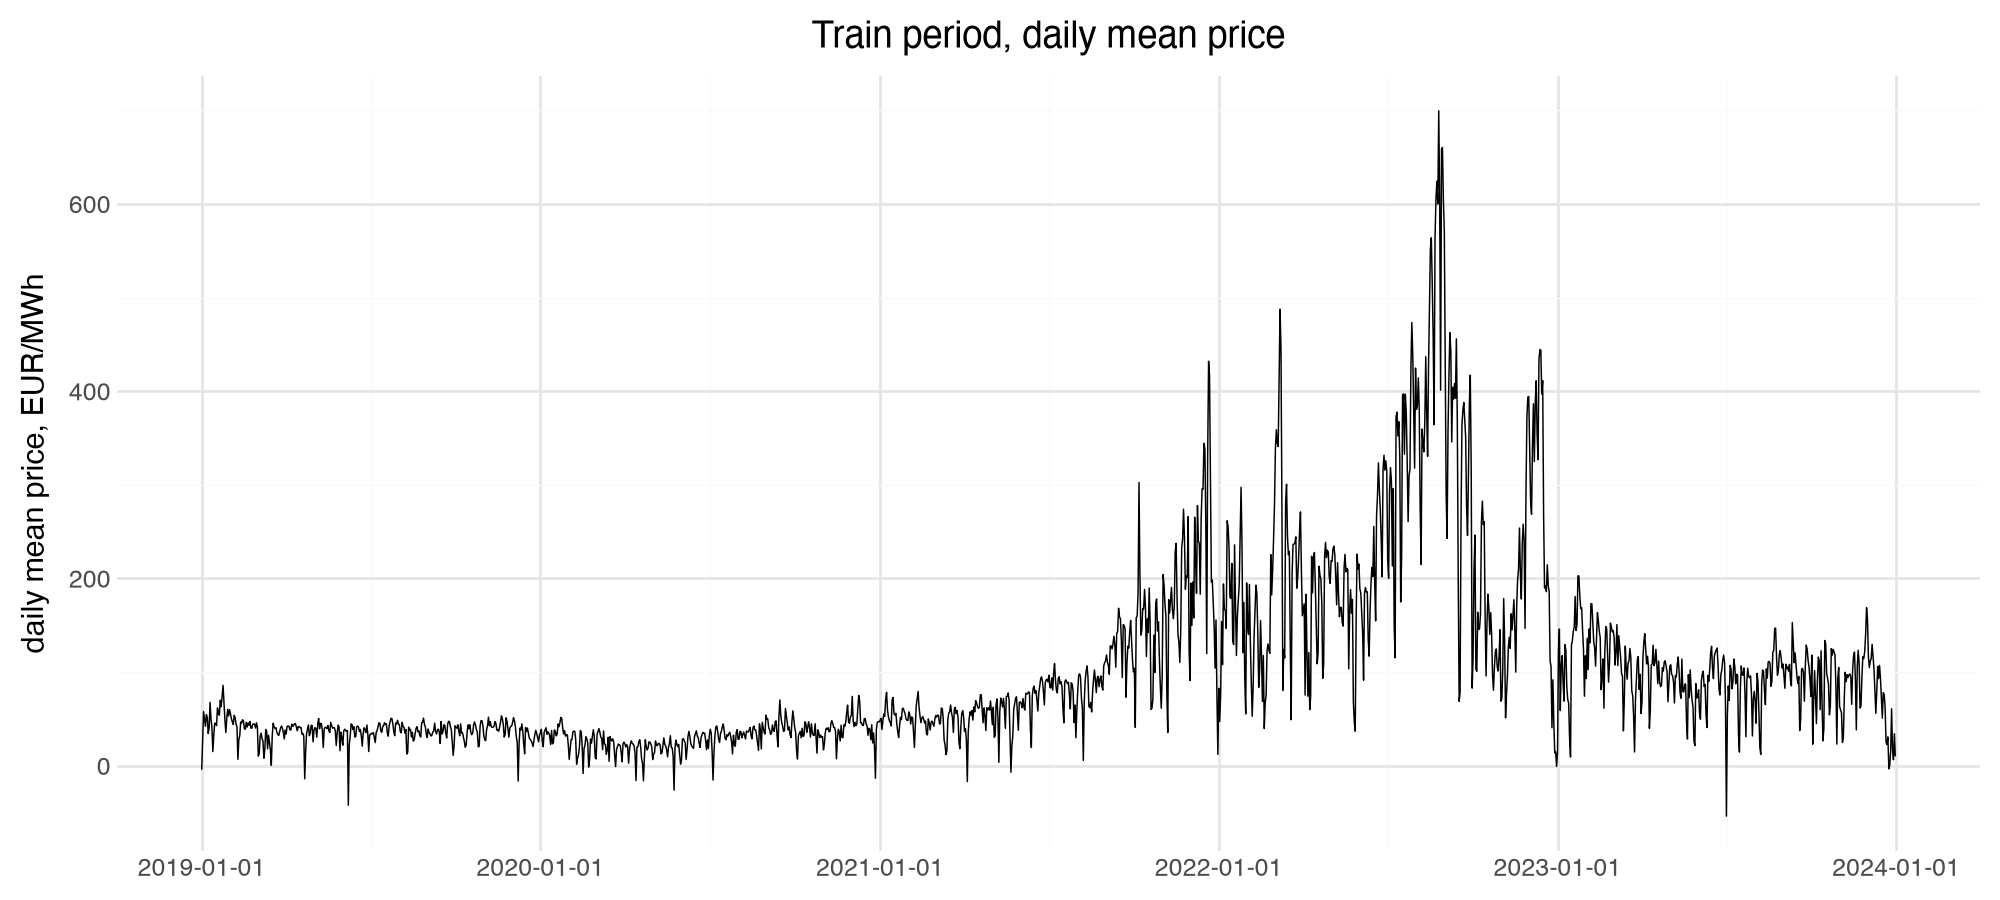

In [11]:
daily = train.group_by("date").agg(price=pl.col("price_da").mean()).sort("date")

(
    ggplot(daily, aes("date", "price"))
    + geom_line(size=0.3)
    + labs(x="", y="daily mean price, EUR/MWh", title="Train period, daily mean price")
)

The level never came back down after the crisis: 2023 averaged 95 EUR/MWh, two and a half times 2019's 38, so anything learned on the early years sits far too low.


Per year: the mean price, how much it swings, and the average miss of the two simplest forecasts.

- `mae_same_hour_yesterday`: forecast each hour with the price 24 hours earlier. `mean(|price_t - price_t-24|)`
- `mae_same_hour_last_week`: the price 168 hours (7 days) earlier. It compares a Monday with last Monday instead of with Sunday, so it catches the weekly cycle that the 24-hour version misses on Mondays and weekends.
- `yesterday_error_share`: `mae_same_hour_yesterday / mean_price`, the miss as a share of the year's price level.


In [12]:
# the miss of each naive forecast: each hour's price minus the price 24 or 168 hours earlier.
# the grid is hourly with no gaps, so differencing by rows is differencing by hours
miss_yesterday = pl.col("price_da").diff(24).abs()
miss_last_week = pl.col("price_da").diff(168).abs()

(
    train.with_columns(miss_yesterday=miss_yesterday, miss_last_week=miss_last_week)
    .group_by("year")
    .agg(
        mean_price=pl.col("price_da").mean(),
        sd_price=pl.col("price_da").std(),
        mae_same_hour_yesterday=pl.col("miss_yesterday").mean(),
        mae_same_hour_last_week=pl.col("miss_last_week").mean(),
    )
    .with_columns(
        yesterday_error_share=pl.col("mae_same_hour_yesterday") / pl.col("mean_price")
    )
    .sort("year")
)

year,mean_price,sd_price,mae_same_hour_yesterday,mae_same_hour_last_week,yesterday_error_share
i32,f64,f64,f64,f64,f64
2019,37.667,15.518,9.342,10.179,0.248
2020,30.471,17.501,9.994,10.314,0.328
2021,96.850,73.681,25.275,31.513,0.261
2022,235.446,142.809,58.190,87.078,0.247
2023,95.175,47.584,27.209,33.643,0.286


The naive forecast misses by 9 EUR/MWh in 2019 and 58 in 2022, yet always by 25% to 33% of that year's mean price. Same hour yesterday also beats same hour last week in every year. MAE alone cannot compare a CV fold that contains 2022 with a calm test year, which is why MASE goes beside it. No column measures fuel cost, so the level has to come from recent prices: lags, yesterday's mean and a longer moving average.


### 3.3 The decision only depends on the shape of the day

The company only chooses when its shift runs, and moving a whole day's prices up or down raises every possible shift by the same amount, which changes nothing it does. What matters is the variance within a day.


Split each year's price movement into two parts. Every hour's price is its day's mean price plus that hour's distance from the mean.

- `between_days_sd`: `sd(daily mean)`, how much whole days move up and down, in EUR/MWh. This is the level, which the decision cannot use.
- `within_day_sd`: `sd(price - its day's mean)`, how far a typical hour sits from its own day's mean, in EUR/MWh. This is the shape the decision ranks.
- `shape_share`: `within² / (within² + between²)`, the shape's share of all price movement. Squared because variances of the two parts add up to the total and SDs do not. At 0.2, 80% of the movement is whole days moving together. The share of the changes that can be attributed to the within day variation


In [13]:
# each hour's distance from its own day's mean price
around_daily_mean = train.with_columns(
    daily_mean=pl.col("price_da").mean().over("date"),
).with_columns(
    deviation=pl.col("price_da") - pl.col("daily_mean"),
)

(
    around_daily_mean.group_by("year")
    .agg(
        between_days_sd=pl.col("daily_mean").std(),
        within_day_sd=pl.col("deviation").std(),
    )
    .with_columns(
        shape_share=pl.col("within_day_sd") ** 2
        / (pl.col("within_day_sd") ** 2 + pl.col("between_days_sd") ** 2)
    )
    .sort("year")
)

year,between_days_sd,within_day_sd,shape_share
i32,f64,f64,f64
2019,11.840,10.030,0.418
2020,13.922,10.604,0.367
2021,66.936,30.798,0.175
2022,128.203,62.917,0.194
2023,35.887,31.247,0.431


In 2021 and 2022 the shape is only 18% to 19% of the price movement, against 37% to 43% in the other years: in 2022 whole days swung by 128 EUR/MWh while hours sat 63 from their day's mean.


Plot the average shape of the day for each year.


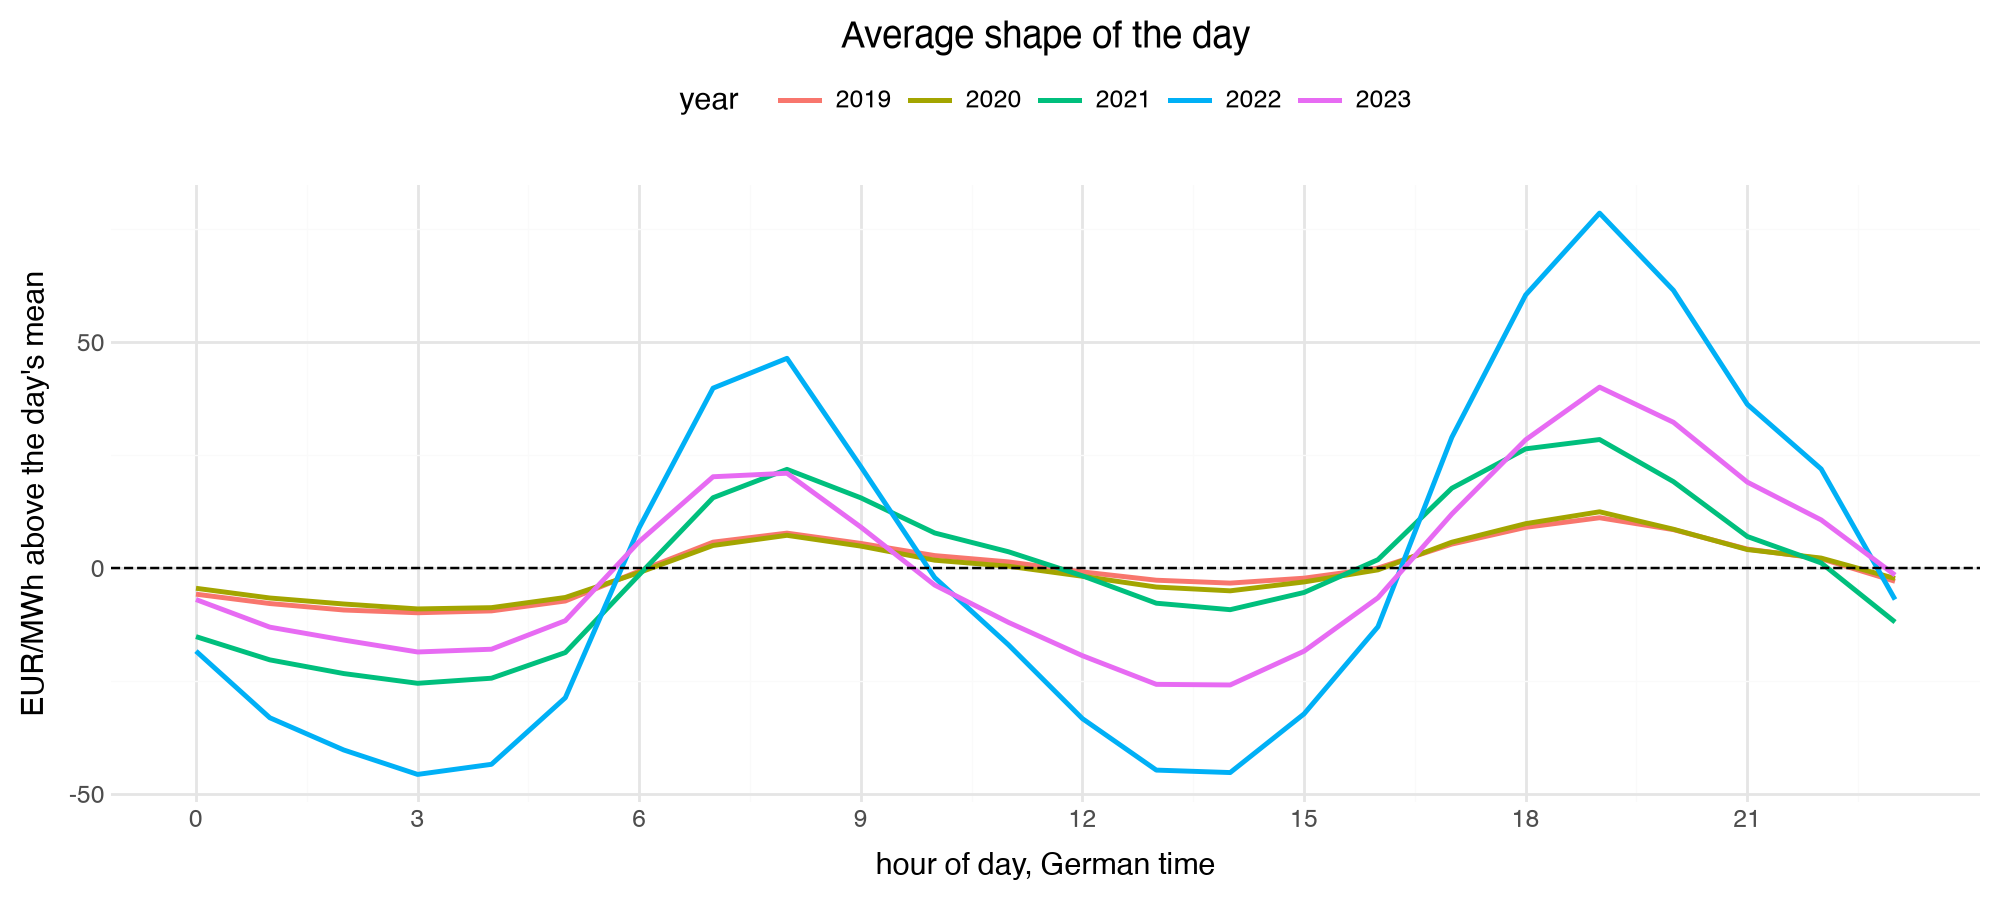

In [14]:
profile = (
    around_daily_mean.group_by("year", "hour")
    .agg(deviation=pl.col("deviation").mean())
    .with_columns(pl.col("year").cast(pl.String))
)

(
    ggplot(profile, aes("hour", "deviation", color="year"))
    + geom_line(size=1)
    + geom_hline(yintercept=0, linetype="dashed")
    + scale_x_continuous(breaks=range(0, 24, 3))
    + labs(
        x="hour of day, German time",
        y="EUR/MWh above the day's mean",
        title="Average shape of the day",
    )
)

The shape moved: by 2023 solar had pushed the cheapest hours from 03:00 to 13:00 to 14:00, so an hour-of-day effect learned on early years points at the wrong hours. The solar and residual-load forecasts have to carry that shift.

With the shape this small a share in the crisis years, a model that minimises error over all hours spends most of its effort on the level. The evaluation needs a shape measure too: the cost of the chosen shift, or the error left after removing each day's mean.


### 3.4 Residual load sets the shape, and its slope moves with the price level


Plot the median price against each forecast, one line per year.


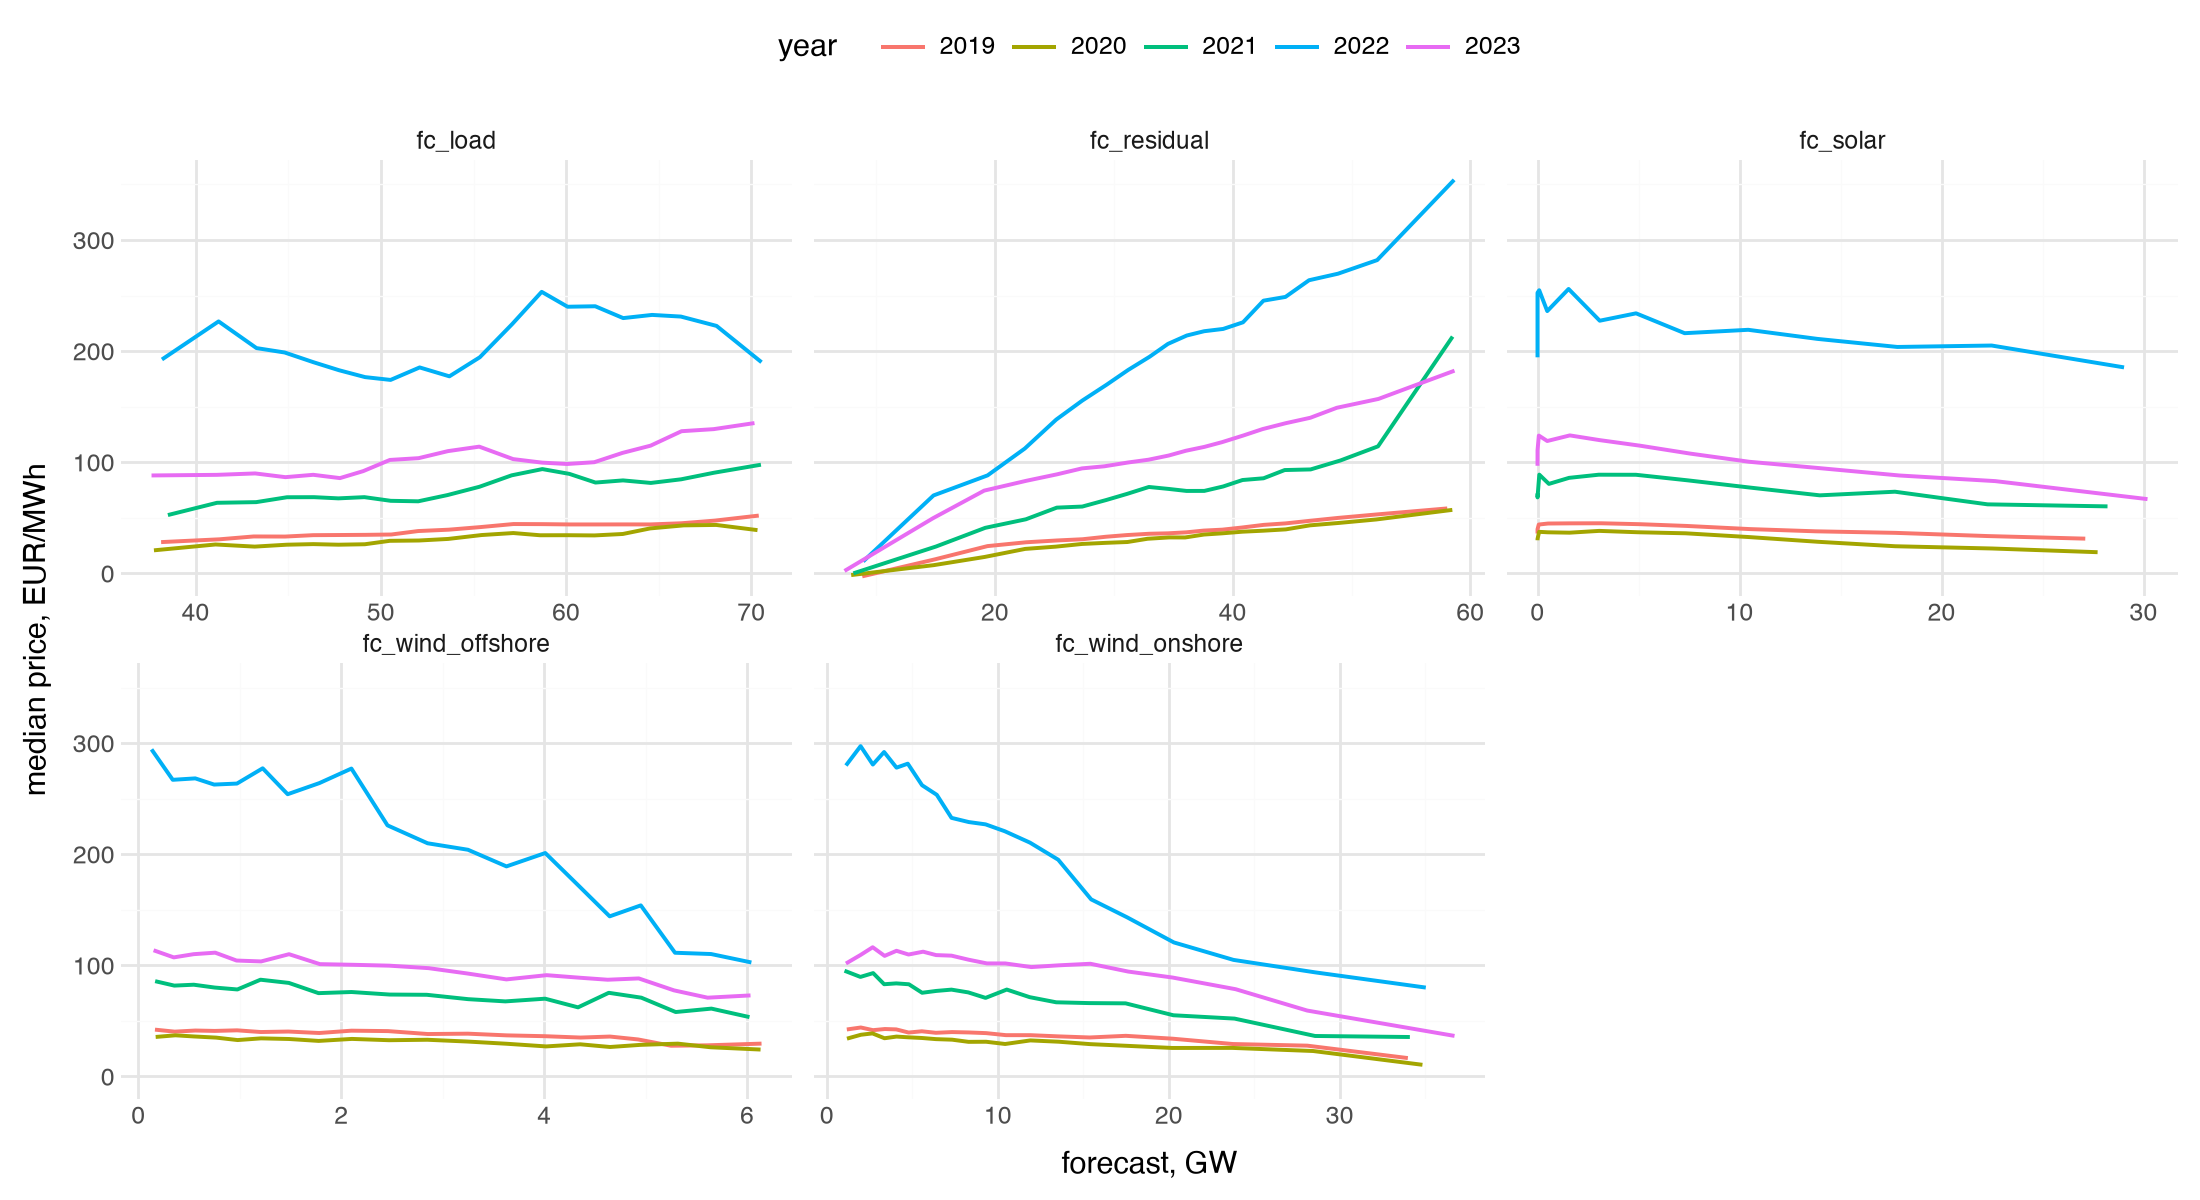

In [15]:
FORECASTS = [
    "fc_load",
    "fc_solar",
    "fc_wind_onshore",
    "fc_wind_offshore",
    "fc_residual",
]

merit = (
    # long format: one row per hour and forecast, so all five share one faceted plot
    train.unpivot(
        index=["year", "price_da"],
        on=FORECASTS,
        variable_name="forecast",
        value_name="mw",
    )
    # cut each forecast into 20 quantile bins with equal hour counts. solar is zero
    # every night, so its lowest quantiles coincide and merge into one bin
    .with_columns(
        bin=pl.col("mw").qcut(20, allow_duplicates=True).over("forecast"),
        year=pl.col("year").cast(pl.String),
    )
    .group_by("forecast", "year", "bin")
    .agg(
        gw=pl.col("mw").median() / 1000,
        price=pl.col("price_da").median(),
        hours=pl.len(),
    )
    .filter(pl.col("hours") >= 50)  # thin bins are noise
)

(
    ggplot(merit, aes("gw", "price", color="year"))
    + geom_line(size=0.8)
    + facet_wrap("~forecast", scales="free_x", ncol=3)
    + labs(x="forecast, GW", y="median price, EUR/MWh")
    + theme(figure_size=(11, 6))
)

Residual load is the only panel where every year's line climbs steadily, and how steeply it climbs changes from year to year. The 2021 line also bends upward above about 52 GW, a scarcity cliff no straight line follows.


Per year, three numbers on residual load and the price:

- `corr_all_hours`: correlation over every hour. It mixes the level and the shape.
- `corr_within_day`: `corr(price - day's mean price, residual - day's mean residual)`. Only asks whether a day's high-residual hours are also its expensive hours, the comparison within the day that the shift choice needs.
- `price_rise_per_gw`: `cov(price, residual) / var(residual) * 1000`, the slope of a straight-line fit: EUR/MWh added per extra GW of residual load.


In [16]:
# price and residual load as distances from their own day's mean
price_dev = pl.col("price_da") - pl.col("price_da").mean().over("date")
residual_dev = pl.col("fc_residual") - pl.col("fc_residual").mean().over("date")

# least-squares slope of price on residual load, scaled from MW to GW
residual_stats = {
    "corr_all_hours": pl.corr("price_da", "fc_residual"),
    "corr_within_day": pl.corr(price_dev, residual_dev),
    "price_rise_per_gw": pl.cov("price_da", "fc_residual")
    / pl.col("fc_residual").var()
    * 1000,
}

# the same three numbers per year, then once for all train years pooled
pl.concat(
    [
        train.group_by("year")
        .agg(**residual_stats)
        .sort("year")
        .with_columns(pl.col("year").cast(pl.String)),
        train.select(year=pl.lit("2019-2023"), **residual_stats),
    ]
)

year,corr_all_hours,corr_within_day,price_rise_per_gw
str,f64,f64,f64
"""2019""",0.847,0.849,1.121
"""2020""",0.827,0.825,1.168
"""2021""",0.582,0.757,3.538
"""2022""",0.623,0.850,7.124
"""2023""",0.882,0.850,3.105
"""2019-2023""",0.387,0.696,3.213


Within the day the correlation holds at 0.76 to 0.85 every year, but the slope runs from 1.1 EUR/MWh per GW in 2019 to 7.1 in 2022, which is why pooling the years drops the all-hours correlation to 0.39.


Within-day correlation of each forecast with the price.


In [17]:
# the within-day correlation from the cell above, once per forecast
train.select(
    [
        pl.corr(price_dev, pl.col(c) - pl.col(c).mean().over("date")).alias(c)
        for c in FORECASTS
    ]
)

fc_load,fc_solar,fc_wind_onshore,fc_wind_offshore,fc_residual
f64,f64,f64,f64,f64
0.269,-0.288,-0.248,-0.150,0.696


Residual load drives the shape at 0.70 pooled, against at most 0.29 for any single component. Because its slope moves with the price level, a linear model needs residual load times a recent price level; trees find that on their own.


### 3.5 Price memory


Correlate the price with itself at every lag up to two weeks.


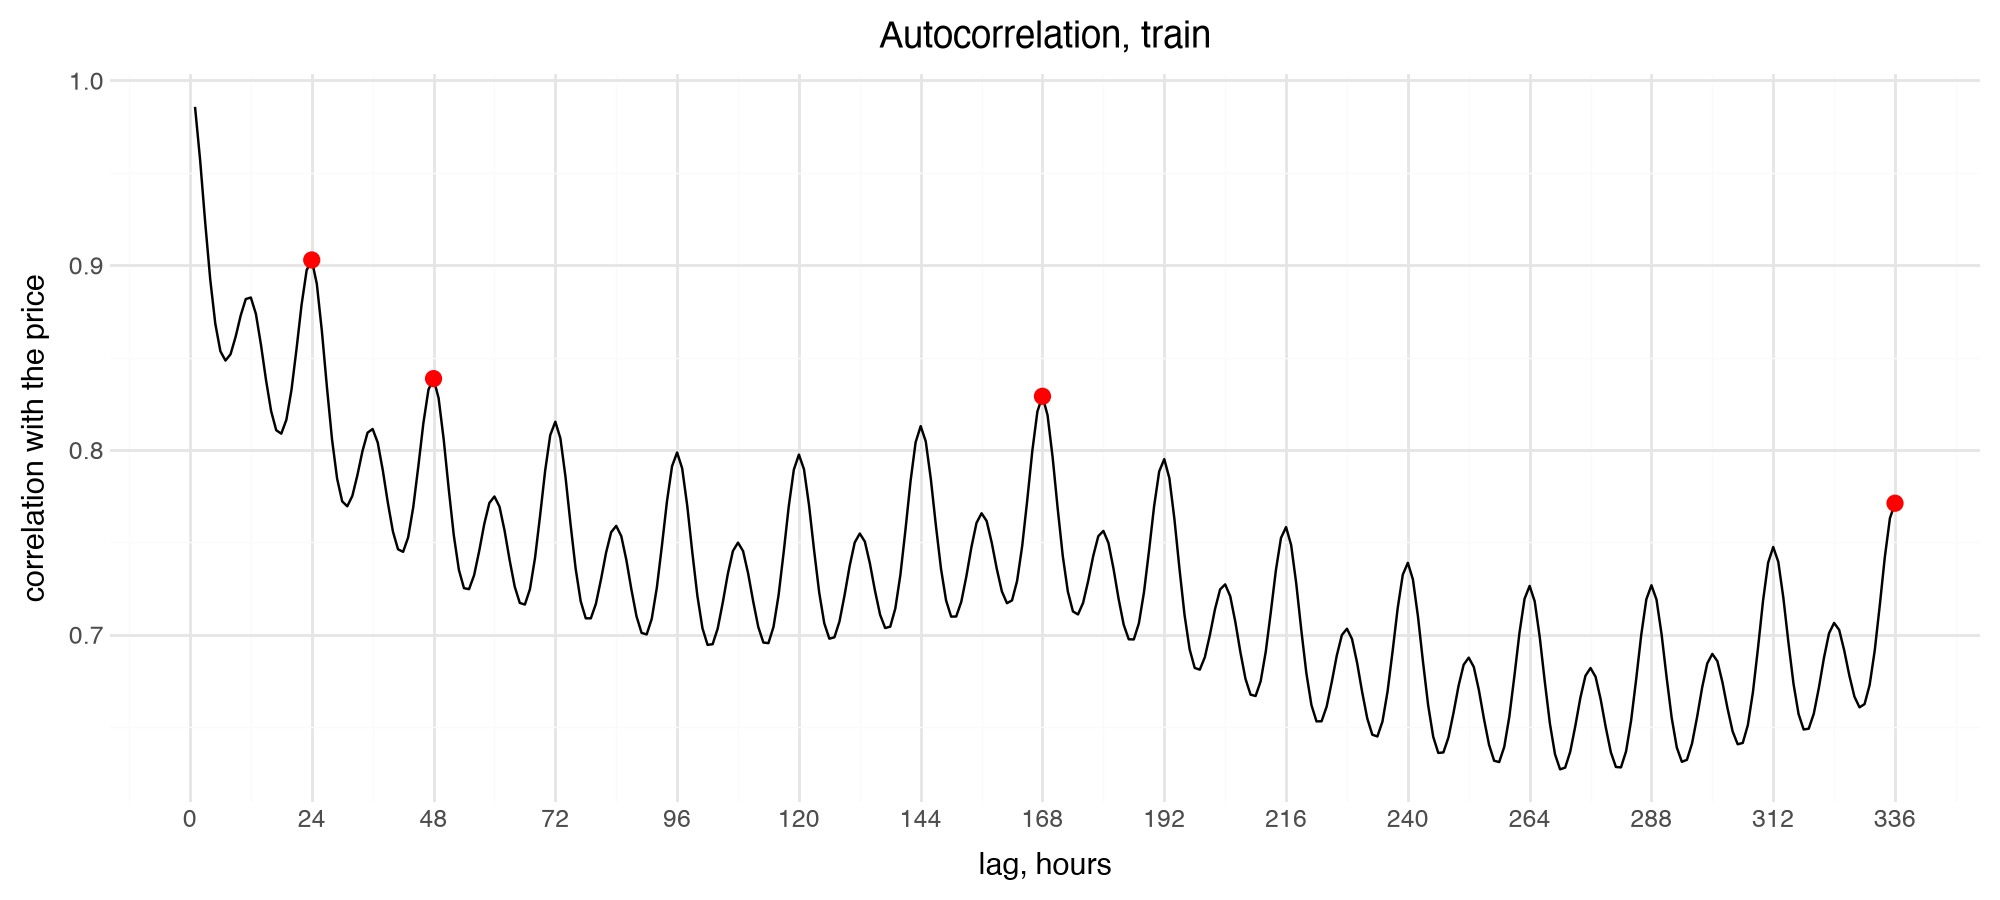

In [18]:
# correlation of the price with itself shifted k hours back, for every k up to 14 days
lags = range(1, 24 * 14 + 1)
autocorrelation = pl.DataFrame(
    {
        "lag_hours": list(lags),
        "corr": [
            train.select(pl.corr("price_da", pl.col("price_da").shift(k))).item()
            for k in lags
        ],
    }
)

(
    ggplot(autocorrelation, aes("lag_hours", "corr"))
    + geom_line()
    + geom_point(
        data=autocorrelation.filter(pl.col("lag_hours").is_in([24, 48, 168, 336])),
        color="red",
        size=2.5,
    )
    + scale_x_continuous(breaks=range(0, 24 * 14 + 1, 24))
    + labs(
        x="lag, hours", y="correlation with the price", title="Autocorrelation, train"
    )
)

Same hour yesterday (0.90) is the strongest legal lag, so it is the baseline. Every 24 hours the correlation peaks again, and the peak at 168 hours stands above its neighbours (0.83 against 0.81 at 144 and 0.80 at 192): that bump is the weekly cycle, a Monday resembling last Monday more than last Sunday. That makes lag 168 the second lag worth keeping.


### 3.6 Neighbouring zones

Same hour is a leak, shown only to measure coupling. Lag 24 is the legal version. Spread asks whether the gap between a zone and Germany on D-1 predicts Germany's move to day D.


Per zone, three correlations with the German price:

- `same_hour_LEAK`: with the zone's price in the same hour. Unknowable at the gate, shown only to measure how tightly the markets move together.
- `lag24`: with the zone's price 24 hours earlier, the legal version. Germany's own row is the number to beat.
- `spread_vs_change`: `corr(zone_t-24 - DE_t-24, DE_t - DE_t-24)`, whether yesterday's gap to the zone predicts Germany's move since yesterday. Positive means that when the zone was more expensive than Germany yesterday, Germany tends to rise.


In [19]:
NEIGHBORS = [c for c in df.columns if c.startswith("price_") and c != "price_da"]

# every price shifted back 24 hours, as new *_lag24 columns
lagged = train.with_columns(
    pl.col(["price_da", *NEIGHBORS]).shift(24).name.suffix("_lag24")
)
# how much the German price moved since the same hour yesterday
change = pl.col("price_da").diff(24)

pl.DataFrame(
    {
        "zone": ["DE-LU itself", *NEIGHBORS],
        "same_hour_LEAK": [
            None,
            *[lagged.select(pl.corr("price_da", z)).item() for z in NEIGHBORS],
        ],
        "lag24": [
            lagged.select(pl.corr("price_da", f"{z}_lag24")).item()
            for z in ["price_da", *NEIGHBORS]
        ],
        "spread_vs_change": [
            None,
            *[
                lagged.select(
                    pl.corr(change, pl.col(f"{z}_lag24") - pl.col("price_da_lag24"))
                ).item()
                for z in NEIGHBORS
            ],
        ],
    }
)

zone,same_hour_LEAK,lag24,spread_vs_change
str,f64,f64,f64
"""DE-LU itself""",null,0.903,null
"""price_FR""",0.934,0.886,0.244
"""price_NL""",0.971,0.903,0.284
"""price_DK1""",0.973,0.883,0.108
"""price_DK2""",0.943,0.858,0.107
"""price_AT""",0.967,0.903,0.255
"""price_PL""",0.858,0.792,0.228
"""price_CH""",0.935,0.894,0.315
"""price_BE""",0.971,0.904,0.277


Same-hour coupling runs from 0.80 (SE4) to 0.98 (CZ). A day back, the best zones (CZ 0.906, BE 0.904) only tie Germany's own lag 24 at 0.903. The spread correlates 0.11 to 0.32 with Germany's move.


Plot the same-hour price correlation between every pair of zones.


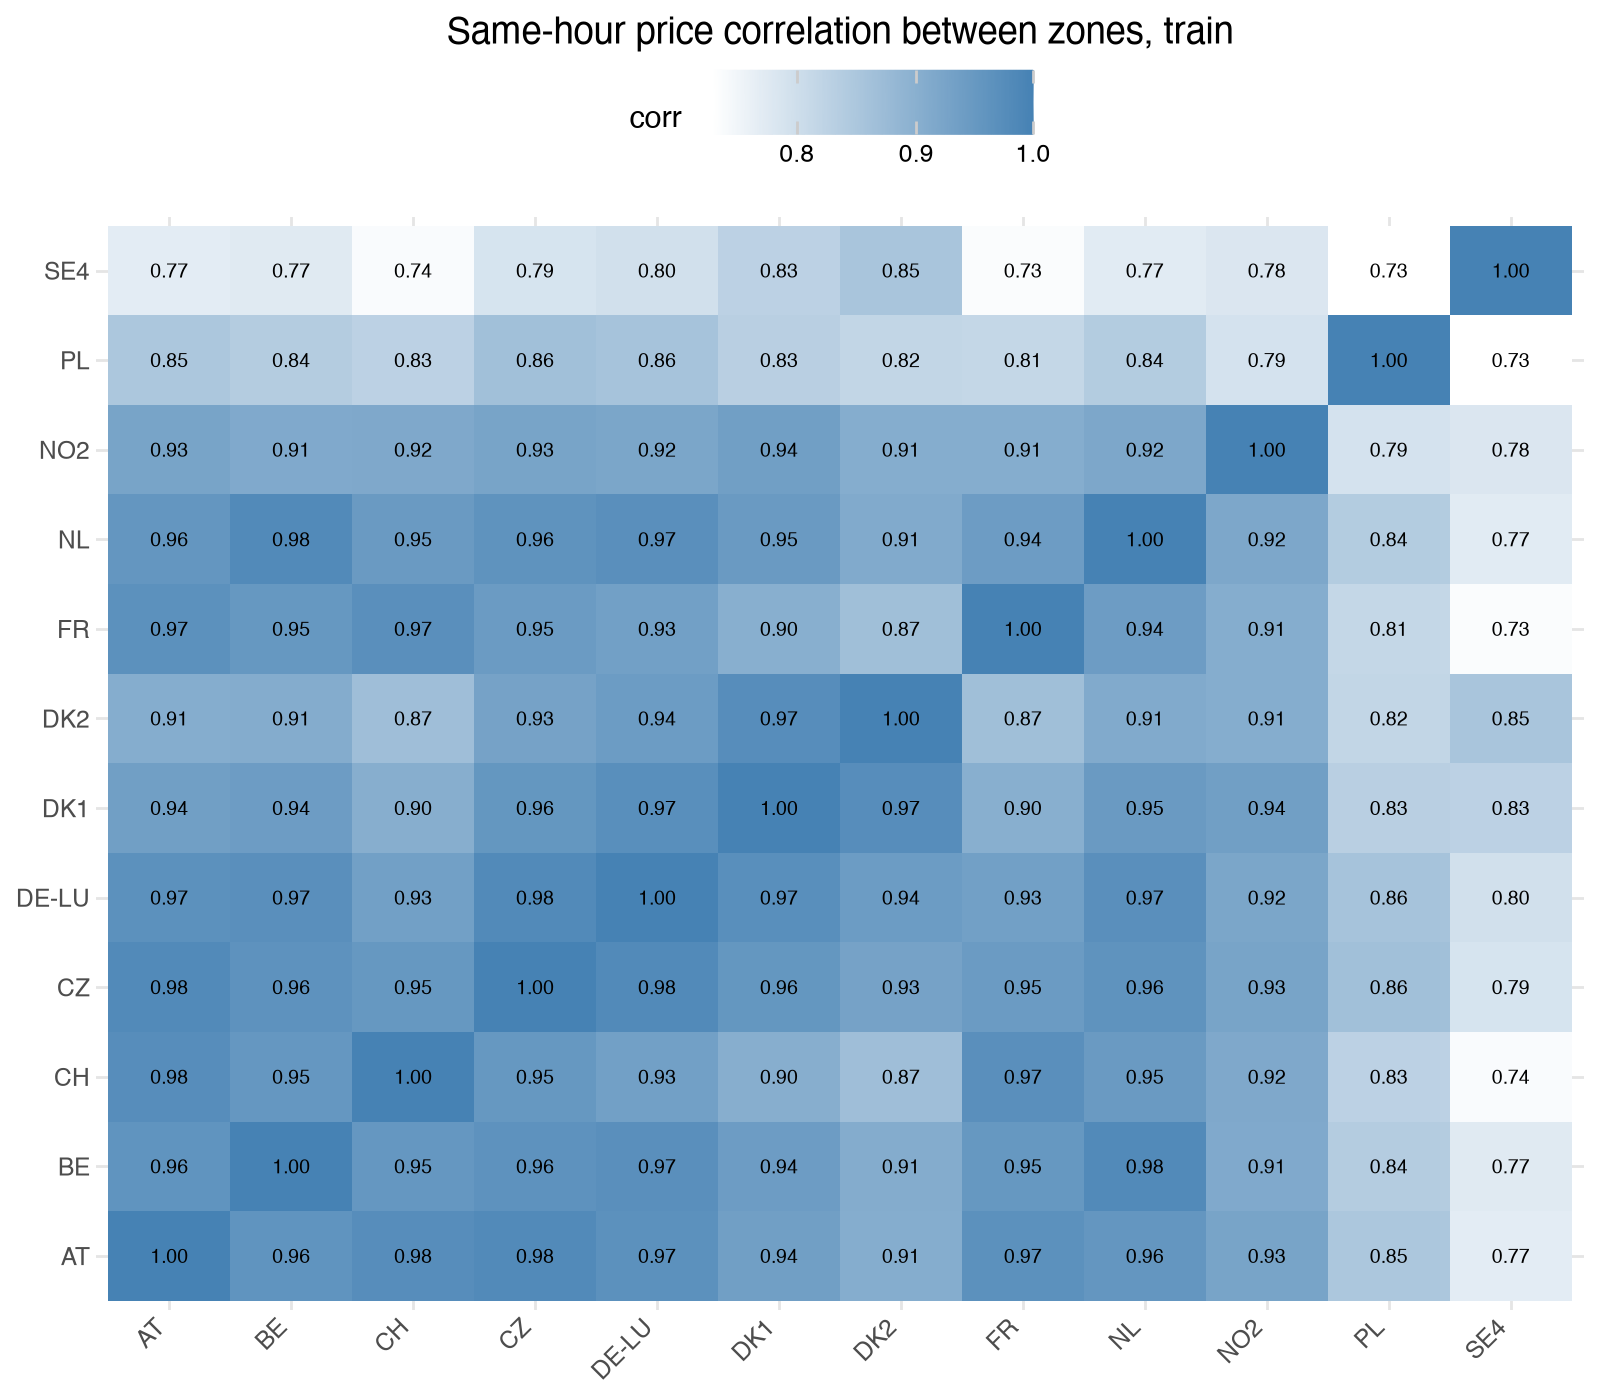

In [20]:
ZONES = ["price_da", *NEIGHBORS]
LABELS = ["DE-LU" if z == "price_da" else z.removeprefix("price_") for z in ZONES]
coupling = (
    train.select([pl.col(z).alias(label) for z, label in zip(ZONES, LABELS)])
    .drop_nulls()
    .corr()
    .with_columns(zone=pl.Series(LABELS))
    .unpivot(index="zone", variable_name="other", value_name="corr")
)

(
    ggplot(coupling, aes("zone", "other", fill="corr"))
    + geom_tile()
    + geom_text(aes(label="corr"), format_string="{:.2f}", size=7)
    + scale_fill_gradient(low="white", high="steelblue")
    + labs(x="", y="", title="Same-hour price correlation between zones, train")
    + theme(axis_text_x=element_text(rotation=45, ha="right"), figure_size=(8, 7))
)

Coupling this tight is what would make a same-hour neighbour price such a damaging leak. Lagged a day, neighbours only tie Germany's own lag 24, so plain neighbour lags add nothing.

The spread is the open question: it predicts Germany's move at up to 0.32 (Switzerland), but that may just be Germany reverting after a cheap day, which its own history already captures. Section 5.2 tests it as its own feature group. For a linear model the central-western zones, at 0.94 to 0.98 with each other, are one variable repeated six times.


### 3.7 Negative prices


Count negative-price hours by hour of day.


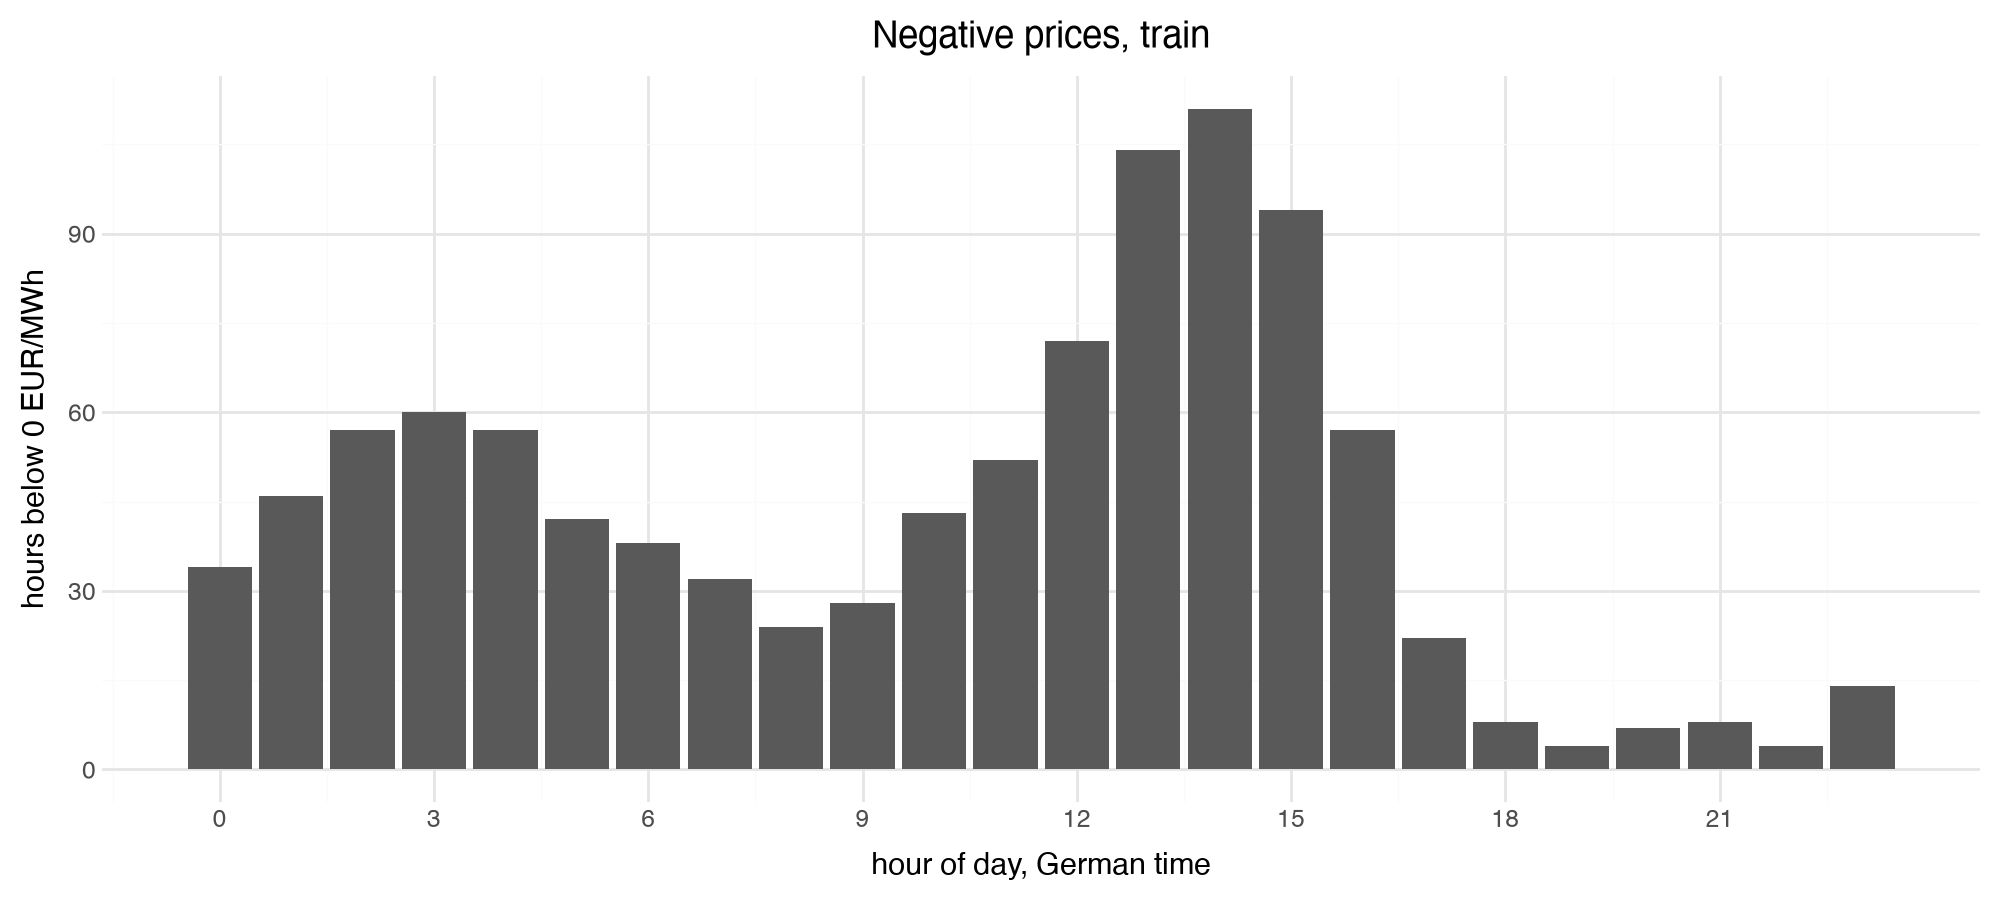

In [21]:
negatives = (
    train.group_by("hour")
    .agg(negative_hours=(pl.col("price_da") < 0).sum())
    .sort("hour")
)

(
    ggplot(negatives, aes("hour", "negative_hours"))
    + geom_col()
    + scale_x_continuous(breaks=range(0, 24, 3))
    + labs(
        x="hour of day, German time",
        y="hours below 0 EUR/MWh",
        title="Negative prices, train",
    )
)

Negative hours peak at 13:00 to 14:00, about 110 each over five years, with a smaller night peak around 03:00 at about 60.


Per year: negative hours, lowest and highest price.


In [22]:
train.group_by("year").agg(
    negative_hours=(pl.col("price_da") < 0).sum(),
    lowest=pl.col("price_da").min(),
    highest=pl.col("price_da").max(),
).sort("year")

year,negative_hours,lowest,highest
i32,u32,f64,f64
2019,211,-90.010,121.460
2020,298,-83.940,200.040
2021,139,-69.000,620.000
2022,69,-19.040,871.000
2023,301,-500.000,524.270


2023 had the most negative hours (301) and the one -500 hour; crisis 2022 had the fewest (69). Negative hours cluster at midday, which is solar, and at night, which is wind meeting low demand. Covering them in a shift pays least, because the company is paid to take the power, and the midday ones fall in the 09:00 to 10:00 starts that section 3.10 finds cheapest. A log transform cannot handle them; asinh can, if diagnostics later ask for a transform.


### 3.8 Calendar


Compare each weekday's mean price with the mean of its week. `eur_vs_week`: `mean(day's mean - week's mean)` in EUR/MWh. `share_of_weeks_cheaper`: share of weeks where that day sits below its week's mean.


In [23]:
(
    train.group_by("date", "weekday")
    .agg(daily_mean=pl.col("price_da").mean())
    # each day's distance from the mean of its calendar week
    .with_columns(week=pl.col("date").dt.truncate("1w"))
    .with_columns(
        vs_week=pl.col("daily_mean") - pl.col("daily_mean").mean().over("week")
    )
    # weekday 1 is Monday
    .group_by("weekday")
    .agg(
        eur_vs_week=pl.col("vs_week").mean(),
        share_of_weeks_cheaper=(pl.col("vs_week") < 0).mean(),
    )
    .sort("weekday")
)

weekday,eur_vs_week,share_of_weeks_cheaper
i8,f64,f64
1,5.136,0.396
2,12.110,0.222
3,11.212,0.230
4,9.454,0.211
5,3.909,0.310
6,-14.723,0.785
7,-27.078,0.893


Weekends lower the level: Sunday sits 27 EUR/MWh below its week, and below it in 89% of weeks. Weekday dummies cover that. Public holidays are not in the data and would look like ordinary weekdays to the model, which makes them a side exploration.


### 3.9 Collinearity among the forecasts


Correlation matrix of the five forecasts.


In [24]:
train.select(FORECASTS).corr().with_columns(forecast=pl.Series(FORECASTS)).select(
    "forecast", *FORECASTS
)

forecast,fc_load,fc_solar,fc_wind_onshore,fc_wind_offshore,fc_residual
str,f64,f64,f64,f64,f64
"""fc_load""",1.000,0.309,0.107,0.119,0.426
"""fc_solar""",0.309,1.000,-0.212,-0.195,-0.267
"""fc_wind_onshore""",0.107,-0.212,1.000,0.710,-0.610
"""fc_wind_offshore""",0.119,-0.195,0.710,1.000,-0.444
"""fc_residual""",0.426,-0.267,-0.610,-0.444,1.000


Only the two wind forecasts correlate (0.71), but `fc_residual` is an exact combination of the other four, so OLS cannot fit all five. Linear models take residual load and solar; trees can take all five.


### 3.10 Which shift simple rules would pick

The decision from the objective, in numbers, before any model exists: where the cheapest shift falls, and how much of the possible saving simple rules already get.


The premium and the shift choice live in `lib/decision.py`: `premium()` gives each hour's staff premium in EUR/MWh, and `best_shift(score)` marks the 8 consecutive hours of each day whose scores add up to the least.


Each rule picks a shift by its own score; every shift is then paid at the real cost.

- `cost`: `price + premium`, the effective EUR/MWh of an hour. The premium is 10 EUR/MWh at night and all weekend, 0 otherwise.
- `hindsight`: the day's actual cheapest shift, the best any forecast could do.
- `standard`: 06:00 to 14:00 every day, a normal early shift and the no-forecast reference.
- `fixed`: the shift that was cheapest on the previous year's average hourly price plus this day's premium. Missing for 2019, which has no previous year in the data.
- `yesterday`: the shift that would have been cheapest on D-1's prices at the same hours, plus the premium.
- `residual`: the shift with the lowest total forecast residual load. Residual load is in GW and cannot be added to a premium in euros, so this rule ignores the premium.
- `*_share`: `(standard - rule) / (standard - hindsight)`, the share of the possible saving a rule gets. 1 is as good as hindsight, 0 no better than the standard shift.


Mark the shift each rule picks on every training day.


In [25]:
RULES = ["hindsight", "standard", "fixed", "yesterday", "residual"]

# each hour's average price in the previous year, attached to the next year's rows
last_year_profile = (
    train.group_by("year", "hour")
    .agg(last_year_mean=pl.col("price_da").mean())
    .with_columns(pl.col("year") + 1)
)

shifts = (
    # lag before the join, since the join does not keep row order
    train.with_columns(price_lag24=pl.col("price_da").shift(24), premium=premium())
    .join(last_year_profile, on=["year", "hour"], how="left")
    .sort("utc_timestamp")
    .with_columns(
        cost=pl.col("price_da") + pl.col("premium"),
        standard=pl.col("hour").is_between(6, 13),
        hindsight=best_shift(pl.col("price_da") + pl.col("premium")),
        fixed=best_shift(pl.col("last_year_mean") + pl.col("premium")),
        yesterday=best_shift(pl.col("price_lag24") + pl.col("premium")),
        residual=best_shift(pl.col("fc_residual")),
    )
)

Plot how often the cheapest shift of the day starts at each hour, per year.


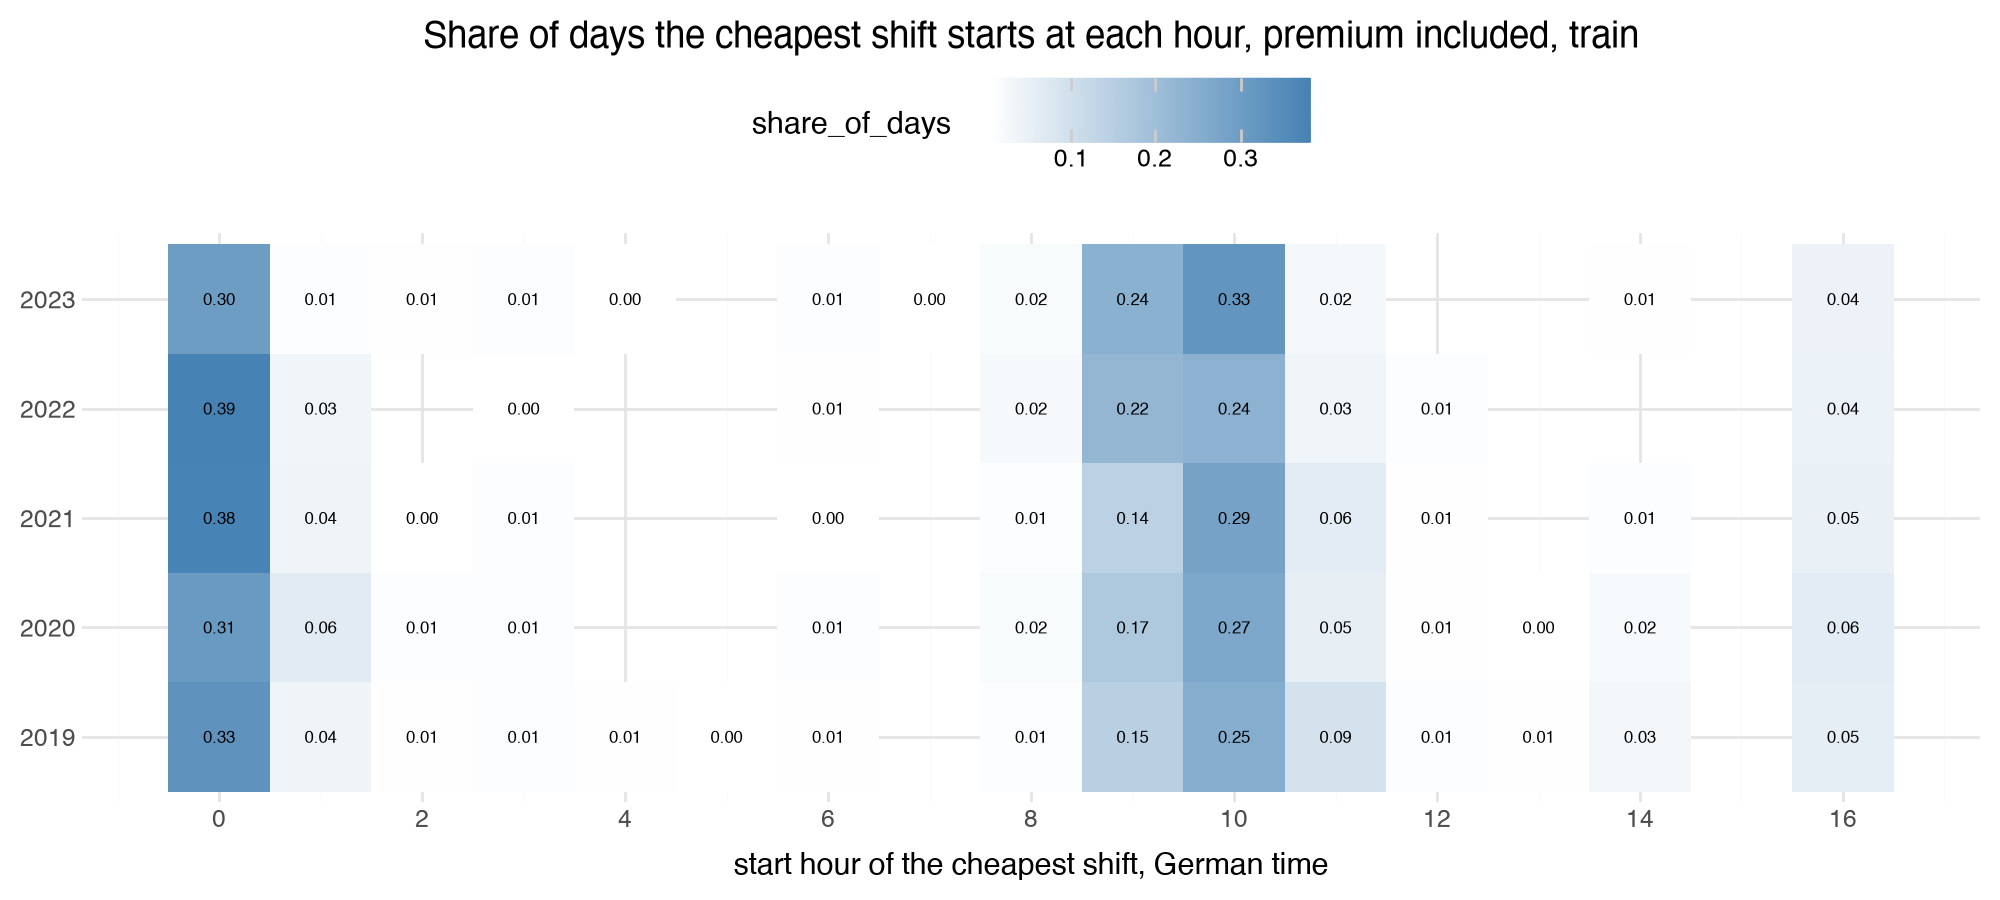

In [26]:
shift_starts = (
    shifts.filter(pl.col("hindsight"))
    .group_by("date")
    .agg(start_hour=pl.col("hour").first(), year=pl.col("year").first())
    .group_by("year", "start_hour")
    .agg(days=pl.len())
    .with_columns(
        share_of_days=pl.col("days") / pl.col("days").sum().over("year"),
        year=pl.col("year").cast(pl.String),
    )
)

(
    ggplot(shift_starts, aes("start_hour", "year", fill="share_of_days"))
    + geom_tile()
    + geom_text(aes(label="share_of_days"), format_string="{:.2f}", size=6)
    + scale_fill_gradient(low="white", high="steelblue")
    + scale_x_continuous(breaks=range(0, 17, 2))
    + labs(
        x="start hour of the cheapest shift, German time",
        y="",
        title="Share of days the cheapest shift starts at each hour, premium included, train",
    )
)

Two starts dominate: 00:00, on 30% to 39% of days, and 09:00 to 10:00, the solar midday, on 40% to 57% of days together. The standard 06:00 start is almost never cheapest, on 1% of days at most.


Per year, the average cost per MWh of the shift each rule picks, premium included, and the share of the possible saving it gets.


In [27]:
shift_cost = shifts.group_by("year").agg(
    **{rule: pl.col("cost").filter(pl.col(rule)).mean() for rule in RULES}
)
shift_cost.with_columns(
    (
        (pl.col("standard") - pl.col(rule)) / (pl.col("standard") - pl.col("hindsight"))
    ).alias(f"{rule}_share")
    for rule in ("fixed", "yesterday", "residual")
).sort("year")

year,hindsight,standard,fixed,yesterday,residual,fixed_share,yesterday_share,residual_share
i32,f64,f64,f64,f64,f64,f64,f64,f64
2019,35.975,42.831,null,38.972,36.881,null,0.563,0.868
2020,28.214,34.802,33.104,31.388,28.909,0.258,0.518,0.895
2021,82.436,106.324,100.157,90.210,83.245,0.258,0.675,0.966
2022,192.233,240.849,223.535,206.195,194.252,0.356,0.713,0.958
2023,74.546,97.416,85.136,81.395,76.151,0.537,0.701,0.930


The residual-load rule gets 87% to 97% of the possible saving, yesterday's prices 52% to 71%, and last year's average 26% to 54%. In 2023 the cheapest shift cost 74.5 EUR/MWh, the standard shift 97.4 and the rule's pick 76.2, leaving 1.6 EUR/MWh on the table.

The rule is still strong but no longer close to perfect: it misses 3% to 13% of the saving, most in the calm years 2019 and 2020, when the 10 EUR/MWh premium is large next to the price gaps and the rule cannot see it. That is the room a price forecast has, since it can weigh the premium in euros.


### 3.11 What the exploration found

Ranked by how much each finding should change the model:

1. Picking the shift with the lowest forecast residual load already gets 87% to 97% of the possible saving against a standard 06:00 shift, but it cannot weigh the night premium. A model is judged by the cost of the shift it picks against this rule, with MAE and RMSE reported beside it.
2. The decision only uses the shape of the day, and in 2021 and 2022 over 80% of the price movement is the level, so the shift cost, not MAE, decides between models.
3. Residual load drives the shape, but its slope went from 1.1 to 7.1 EUR/MWh per GW. Linear models need residual load times a recent price level.
4. The yearly mean price went from 30 EUR/MWh in 2020 to 235 in 2022, almost 8 times as high, and no column measures fuel cost. Price lags (24, 48, 168 hours), yesterday's mean and a 30-day mean have to carry it, with MASE beside MAE.
5. Solar moved the cheapest hours from 03:00 to 13:00 inside train, so fixed hour effects go stale. The solar forecast or per-hour models carry the shift.
6. Same hour yesterday is the MAE baseline: strongest lag at 0.90, and it beat same hour last week every year. For choosing the shift it is weak, at 52% to 71% of the possible saving.
7. Weekends lower the level by 15 to 27 EUR/MWh. Weekday dummies cover it; holidays are missing.
8. Neighbour prices add nothing as plain lags. Only the spread might, unproven.
9. Negative prices fill 2.3% of train hours, so no log transform; asinh if one is needed.

#### To keep in mind going forward

1. The TSO forecasts arrive after the 11:55 gate (section 3.1), so every result assumes the company buys a vendor forecast of similar quality.
2. Fold 1's score runs slightly optimistic, because the features were shaped partly by looking at 2023, its validation year.
3. The -500 EUR/MWh hour and the 2022 spikes are auction results, not errors, so they stay in, and the model is scored on them.
4. From 2025-10-01 the auction clears in quarter hours, and the target there is the hourly mean of the four. The last three months of 2025 and all of 2026 are scored on that constructed hourly price, not on one that cleared as an hour.
5. Residual load is built in section 1.2 as load minus solar and wind, so it adds nothing the four forecasts do not already hold. A linear model gets residual load and solar instead of all five, because a column that is an exact sum of others makes its coefficients meaningless.


## 4. Cleaning and features

### 4.1 Cleaning

The cleaning decisions that follow from section 3.11, applied to the whole table because each one only looks backwards:

1. Forward-fill the neighbour prices, which only fills the missing Dutch day (2026-10-10). It uses earlier values only, so it is allowed on test.
2. Keep every extreme, the -500 hour and the 2022 spikes included.
3. No target transform yet. Section 6 tests asinh.
4. Keep the hourly mean of the quarter-hour prices as the target after 2025-10-01.
5. Drop the first 30 days of the data from training only, because their 30-day mean and lag 168 are missing. No test row is dropped.


Forward-fill the neighbour prices.


In [28]:
clean = df.sort("utc_timestamp").with_columns(pl.col(NEIGHBORS).forward_fill())
clean.null_count().sum_horizontal().item()

0

No missing data is left.


### 4.2 Hypotheses and features

Each finding from section 3.11 becomes a hypothesis and a feature group:

| | Hypothesis | Feature group | Columns |
|---|---|---|---|
| H1 | the shape follows the clock and the week (findings 5, 7) | `calendar` | hour, weekday, month, weekend flag, all in German local time |
| H2 | residual load sets the shape (finding 3) | `fundamentals` | the forecasts. Linear models get `fc_residual` and `fc_solar` only, since residual load is built from the other four |
| H3 | recent prices carry the level (findings 4, 6) | `price-memory` | same-hour lags 24, 48 and 168; D-1's mean, min and max; 7-day and 30-day means of the daily price |
| H4 | the residual-load slope scales with the level (finding 3) | `level-interaction` | `residual_x_level`, see below |
| H5 | yesterday's gap to the neighbours predicts Germany's move (finding 8) | `neighbour-spreads` | one spread per zone, see below |

Every feature is known at 11:55 on D-1: lags of 24 hours or more reach back into D-1 at the latest, and the daily statistics end at the close of D-1.


Compute each day's mean, min and max price, the 7-day and 30-day means of the daily mean, and attach them to the following day.


In [29]:
daily_stats = (
    clean.group_by("date")
    .agg(
        prev_day_mean=pl.col("price_da").mean(),
        prev_day_min=pl.col("price_da").min(),
        prev_day_max=pl.col("price_da").max(),
    )
    .sort("date")
    .with_columns(
        mean_7d=pl.col("prev_day_mean").rolling_mean(7),
        mean_30d=pl.col("prev_day_mean").rolling_mean(30),
    )
    # move every statistic one day forward: day D only sees days up to D-1
    .with_columns(pl.col("date") + pl.duration(days=1))
)

Two engineered columns need a definition:

- `spread_<zone>`, for H5: `zone_t-24 - DE_t-24`, the zone's price minus Germany's at the same hour on D-1, in EUR/MWh. Positive means the zone was more expensive.
- `residual_x_level`, for H4: `fc_residual / 1000 * mean_30d`, residual load in GW times the 30-day mean price. A linear model can then let the residual-load slope grow with the price level, 1.1 EUR/MWh per GW at 2019 prices against 7.1 at 2022 prices.


Add the lags, the spreads, the calendar flags and the daily statistics to every hour.


In [30]:
SPREADS = [f"spread_{z.removeprefix('price_')}" for z in NEIGHBORS]

features = (
    clean.with_columns(
        # yesterday's gap between each zone and Germany at the same hour
        [
            (pl.col(zone).shift(24) - pl.col("price_da").shift(24)).alias(spread)
            for zone, spread in zip(NEIGHBORS, SPREADS)
        ],
        # the grid is hourly with no gaps, so shifting by rows is shifting by hours
        price_lag24=pl.col("price_da").shift(24),
        price_lag48=pl.col("price_da").shift(48),
        price_lag168=pl.col("price_da").shift(168),
        month=pl.col("date").dt.month(),
        is_weekend=pl.col("weekday") >= 6,
    )
    .join(daily_stats, on="date", how="left")
    .sort("utc_timestamp")
    .with_columns(residual_x_level=pl.col("fc_residual") / 1000 * pl.col("mean_30d"))
)

GROUPS: dict[str, list[str]] = {
    "calendar": ["hour", "weekday", "month", "is_weekend"],
    "fundamentals": FORECASTS,
    "price-memory": [
        "price_lag24",
        "price_lag48",
        "price_lag168",
        "prev_day_mean",
        "prev_day_min",
        "prev_day_max",
        "mean_7d",
        "mean_30d",
    ],
    "level-interaction": ["residual_x_level"],
    "neighbour-spreads": SPREADS,
}
ALL_FEATURES = [c for cols in GROUPS.values() for c in cols]

Split the feature table into the three sets the rest of the notebook uses, and show the size and dates of each:

- `dev`: 2019 to 2024, everything the folds train and validate on, without the first 30 days, which lack a full price history.
- `test_2025`: 2025, scored once by the final model; its score is the final result.
- `reserve_2026`: 2026-01-01 to 2026-10-11, scored once at the end as a bonus, or the test for a redone model if 2025 forced one.


In [31]:
dev = features.filter(pl.col("year") < TEST_FROM).drop_nulls(ALL_FEATURES)
test_2025 = features.filter(pl.col("year").is_between(TEST_FROM, RESERVE_FROM - 1))
reserve_2026 = features.filter(pl.col("year") >= RESERVE_FROM)

parts: list[tuple[str, pl.DataFrame]] = [
    ("dev", dev),
    ("test", test_2025),
    ("reserve", reserve_2026),
]
pl.DataFrame(
    [
        {
            "set": name,
            "hours": part.height,
            "first_day": part["date"].min(),
            "last_day": part["date"].max(),
            "missing_feature_values": part.select(ALL_FEATURES)
            .null_count()
            .sum_horizontal()
            .item(),
        }
        for name, part in parts
    ]
)

set,hours,first_day,last_day,missing_feature_values
str,i64,date,date,i64
"""dev""",51888,2019-01-31,2024-12-31,0
"""test""",8760,2025-01-01,2025-12-31,0
"""reserve""",6815,2026-01-01,2026-10-11,0


All three sets cover the periods defined above, and none has a missing feature value.


## 5. Modelling

### 5.1 Comparing the models

Three methods on the same two validation years, beside the reference rules. The choice follows section 3 and the open benchmark for day-ahead prices of Lago et al. 2021:

- `lasso-then-xgboost`. Most of the price follows a steady pattern: the daily and weekly shape, and the link to residual load and recent prices (findings 3, 6 and 7). A Lasso fits that pattern, and the trees then fit what it gets wrong, such as the residual-load slope moving with the price level.
- `xgboost`, the same method with the Lasso stage switched off, which shows whether that stage earns its place.
- `lear`, the standard linear model in that benchmark, which `project.md` names too. It is one Lasso per delivery hour on its own inputs: every hour of the price on D-1, D-2, D-3 and D-7, the load and renewable forecasts for D, D-1 and D-7, and the weekday. Prices pass through asinh, and AIC picks each hour's penalty, so it has no settings to choose. It trains on the two years before each validation year, the window later papers use, and is refitted once a year like the other two; the published version refits every day, which would likely help it. LEAR came out of a short search of that benchmark and later papers on arXiv on 2026-10-17, after the rest of this section had first run.

The two tree methods run at the libraries' default settings, on the same features: 100 trees up to 6 levels deep at a learning rate of 0.3 for XGBoost, and a penalty of 1 for the Lasso. Section 5.3 compares them again at their best.

Lasso alone is left out: it is Lasso-then-XGBoost without its trees, so on training data it can only do worse, and section 3 found a bend a linear model cannot follow (finding 3).

Other methods were considered and not compared, ranked by how likely each was to help:

- LambdaRank, ranking the day's 17 possible shifts directly. Each row would have to become a whole shift with its own features, a few hours of work, while the residual-load rule alone already gets 87% to 97% of the possible saving (section 3.10).
- Separate models for the daily level and the hourly shape. The decision only needs the shape (finding 2), but this doubles the models to build and read for a gain nothing in section 3 put a size on.
- One XGBoost model per delivery hour. LEAR already tests the per-hour design `project.md` suggests, and the trees can split on the hour themselves.
- A neural network. Later papers find one beats LEAR, but it has far more settings, costs far more to build and to read, and no finding points to a pattern the trees would miss.

Every method and setting in this section is scored by `evaluate` in `lib/evaluation.py`, once for each validation year, 2023 and 2024. Tables show the mean of the two years:

- `saving_share`, which decides: `(standard - shift_cost) / (standard - hindsight)`. Each term is a year's average cost in EUR/MWh, electricity plus premium, of one kind of shift: the standard 06:00 to 14:00 shift, the shift the method picks, and the cheapest shift in hindsight. 100% matches hindsight, 0% is no better than the standard shift. It comes from the year's totals rather than an average over days, so a day with more to save counts for more.
- `saving_share_fold_sd`: the standard deviation of the two yearly saving shares, how far the score moves between 2023 and 2024. It is the noise in the rules below, and resting on two numbers, it is a rough one.
- `shift_cost`: the average EUR/MWh, electricity plus premium, of the shifts a method picks. A price forecast picks the shift with the lowest forecast price plus premium.
- `right_shift_share`: the share of days on which the method picks the cheapest shift.
- `mae` and `rmse` in EUR/MWh, and `mase`, the MAE over that of same hour yesterday. `rmse` squares each miss before averaging, so a few large misses raise it far more than they raise MAE. These are reported for the course and only decide a tie.
- `mae_fold_sd`: the standard deviation of the two yearly MAEs, the noise for MAE.

Three rules decide every choice from here on, each fixed before the comparison it settles:

1. Between two methods: the higher saving share wins if it leads by more than the larger of their two `saving_share_fold_sd`; a smaller gap is a tie. On a tie, the lower MAE wins if it leads by more than the larger `mae_fold_sd`. If both tie, the simpler method wins: XGBoost alone over Lasso-then-XGBoost, and either over LEAR, which is 24 separate models with about 250 inputs each.
2. A method's best setting: among the settings whose saving share lies within the top setting's fold SD, the one with the lowest MAE.
3. A wider search's best replaces a setting already chosen only if it wins under rule 1, since the best of many noisy scores looks better than it is. Otherwise the current setting stays.

These rules were settled on 2026-10-17, after 5.1 and 5.2 first ran with a looser one, where any MAE lead broke a tie. Applied in full, they change two early calls; both are noted where they happen, with what the looser rule decided.

The references: `same-hour-yesterday` and `training-mean`, required by `project.md`; `standard-shift`, which scores 0 by definition; `last-year-profile`, the shift that was cheapest on last year's average hourly price; and `residual-load-rule`, which ignores the premium.


The tools from `lib/` used from here on, so the code there never has to be opened:

- `LassoThenXGB(columns, linear_columns, alpha, **xgb_settings)`, in `lib/modeling.py`, is the two-stage method. A Lasso fits the price on `linear_columns`, with the calendar one-hot encoded and the rest standardised; XGBoost then fits what the Lasso got wrong, on every column; the prediction is the sum of the two. `columns` lists every column of the matrix it gets, in order.
- `XGBRegressor`, straight from the xgboost library, is XGBoost alone.
- `lear_forecast(fit, predict)`, in `lib/modeling.py`, builds LEAR's inputs from the hourly table, fits the 24 Lassos on the last two years of `fit` and returns a price forecast for every hour of `predict`.
- `summarise_folds(scores)`, in `lib/evaluation.py`, averages a list of yearly scores and adds their fold SDs, as `cross_validate` does. LEAR builds its own inputs, so it is scored one year at a time with `evaluate` and summed up with this.
- `cross_validate(model, columns, data, FOLDS)`, in `lib/evaluation.py`: for each fold, fits a fresh copy of the model on the years before the validation year, predicts that year and scores it with `evaluate`. Returns the scores averaged over the two folds with `saving_share_fold_sd` and `mae_fold_sd`, the noise between folds, and the out-of-fold predictions.
- `evaluate(frame, score, pick_with_premium, report_error)`, in `lib/evaluation.py`, picks each day's shift from `score` and computes the scores listed above. `pick_with_premium=False` is for a score that is not in EUR/MWh, such as residual load, which picks without adding the premium. `report_error=False` skips MAE, RMSE and MASE for a score that is not an hourly price forecast.
- `df_to_np(frame, columns)`, in `lib/modeling.py`, turns the named columns into the number matrix a model takes.
- `AsinhTarget(model)`, in `lib/modeling.py` and used in section 6, fits the model on asinh(price) and converts its predictions back with sinh.


Fix the feature columns each part of the two tree methods sees: every group for now, with the linear version of the fundamentals for the Lasso.


In [32]:
LINEAR_FUNDAMENTALS = [
    "fc_residual",
    "fc_solar",
]  # residual load is an exact sum of the other four


def columns_for(groups: list[str], linear: bool = False) -> list[str]:
    """The feature columns of the named groups, with the linear fundamentals if `linear`."""
    return [
        c
        for g in groups
        for c in (LINEAR_FUNDAMENTALS if linear and g == "fundamentals" else GROUPS[g])
    ]


TREE_COLUMNS = columns_for(list(GROUPS))
LINEAR_COLUMNS = columns_for(list(GROUPS), linear=True)
ALL_COLUMNS = list(dict.fromkeys(TREE_COLUMNS + LINEAR_COLUMNS))

Score the reference rules on each validation year and average them.


In [33]:
reference_rows: list[dict[str, str | float | None]] = []
for fit, valid in make_folds(dev, FOLDS).values():
    last_year = (
        fit.filter(pl.col("year") == fit["year"].max())
        .group_by("hour")
        .agg(profile=pl.col("price_da").mean())
    )
    profile = valid.join(last_year, on="hour", how="left").sort("utc_timestamp")[
        "profile"
    ]
    standard = np.where(valid["hour"].is_between(6, 13).to_numpy(), 0.0, 1.0)
    reference_rows += [
        {"method": "same-hour-yesterday"}
        | evaluate(valid, valid["price_lag24"].to_numpy()),
        {"method": "training-mean"}
        | evaluate(valid, np.full(valid.height, fit["price_da"].mean())),
        {"method": "standard-shift"}
        | evaluate(valid, standard, pick_with_premium=False, report_error=False),
        {"method": "last-year-profile"}
        | evaluate(valid, profile.to_numpy(), report_error=False),
        {"method": "residual-load-rule"}
        | evaluate(
            valid,
            valid["fc_residual"].to_numpy(),
            pick_with_premium=False,
            report_error=False,
        ),
    ]

references = (
    pl.DataFrame(reference_rows)
    .group_by("method", maintain_order=True)
    .agg(pl.all().mean())
)

Cross-validate the two tree methods at default settings, score LEAR on the same two years, and put all three beside the references.


In [34]:
comparison_rows: list[dict[str, str | float | None]] = []
for name, model, columns in (
    ("lasso-then-xgboost", LassoThenXGB(ALL_COLUMNS, LINEAR_COLUMNS), ALL_COLUMNS),
    ("xgboost", XGBRegressor(random_state=0), TREE_COLUMNS),
):
    summary, _ = cross_validate(model, columns, dev, FOLDS)
    comparison_rows.append({"method": name} | summary)

lear_scores = [
    evaluate(valid, lear_forecast(fit, valid))
    for fit, valid in make_folds(dev, FOLDS).values()
]
comparison_rows.append({"method": "lear"} | summarise_folds(lear_scores))

pl.concat([pl.DataFrame(comparison_rows), references], how="diagonal_relaxed").select(
    "method",
    "saving_share",
    "saving_share_fold_sd",
    "shift_cost",
    "right_shift_share",
    "mae",
    "mae_fold_sd",
    "rmse",
    "mase",
).sort("saving_share", descending=True)

method,saving_share,saving_share_fold_sd,shift_cost,right_shift_share,mae,mae_fold_sd,rmse,mase
str,f64,f64,f64,f64,f64,f64,f64,f64
"""lasso-then-xgboost""",0.956,0.013,65.436,0.709,17.486,1.204,26.945,0.636
"""xgboost""",0.954,0.003,65.488,0.676,18.854,3.571,28.275,0.686
"""residual-load-rule""",0.941,null,65.785,0.689,null,null,null,null
"""lear""",0.935,0.012,65.906,0.689,17.094,2.198,28.845,0.621
"""same-hour-yesterday""",0.737,null,70.338,0.473,27.513,null,42.301,1.000
"""last-year-profile""",0.553,null,74.447,0.284,null,null,null,null
"""standard-shift""",0.000,null,86.789,0.007,null,null,null,null
"""training-mean""",-0.220,null,91.671,0.066,36.614,null,52.428,1.330


The two tree methods beat every reference, and LEAR falls just short of the residual-load rule, 93.5% of the possible saving against 94.1%.

LEAR loses to both tree methods beyond the noise: 93.5% against 95.6% and 95.4%, gaps of 2.1 and 1.9 points against larger fold SDs of 1.3 and 1.2. Yet its MAE is the lowest of the three, 17.1 EUR/MWh against 17.5 and 18.9. Pricing each hour well is not the same as ranking the hours well, and the ranking is what picks the shift (finding 2). LEAR stops here.

Under rule 1 the tree methods tie on both counts: the saving-share gap of 0.2 points is inside the larger fold SD of 1.3, and the MAE gap of 1.4 EUR/MWh is inside the larger MAE fold SD of 3.6, so the simpler XGBoost alone goes forward. The looser rule first used sent Lasso-then-XGBoost forward on its lower MAE instead, which is why 5.2 tests the feature groups on it; that order does not decide the final model, since 5.3 compares both at their best. Their edge over the residual-load rule, about 1.5 points, is only just above the noise, and whether it holds is the question the rest of the notebook has to answer.


### 5.2 Choosing feature groups

Add the feature groups to Lasso-then-XGBoost one at a time, and keep a group only if it wins under rule 1 against the set without it: a saving-share gain beyond the fold SD or, inside that noise, an MAE cut beyond the MAE fold SD.


Cross-validate Lasso-then-XGBoost on growing sets of feature groups.


In [35]:
STEPS = [
    ["calendar", "fundamentals"],
    ["calendar", "fundamentals", "price-memory"],
    ["calendar", "fundamentals", "price-memory", "level-interaction"],
    [
        "calendar",
        "fundamentals",
        "price-memory",
        "level-interaction",
        "neighbour-spreads",
    ],
]

group_rows: list[dict[str, str | float | None]] = []
for groups in STEPS:
    linear = columns_for(groups, linear=True)
    columns = list(dict.fromkeys(columns_for(groups) + linear))
    summary, _ = cross_validate(LassoThenXGB(columns, linear), columns, dev, FOLDS)
    group_rows.append({"last_group_added": groups[-1]} | summary)

pl.DataFrame(group_rows).select(
    "last_group_added",
    "saving_share",
    "saving_share_fold_sd",
    "right_shift_share",
    "mae",
    "mae_fold_sd",
    "rmse",
    "mase",
)

last_group_added,saving_share,saving_share_fold_sd,right_shift_share,mae,mae_fold_sd,rmse,mase
str,f64,f64,f64,f64,f64,f64,f64
"""fundamentals""",0.644,0.057,0.442,39.717,10.530,54.694,1.447
"""price-memory""",0.958,0.002,0.719,19.128,1.429,29.317,0.696
"""level-interaction""",0.962,0.009,0.709,19.094,2.604,29.288,0.695
"""neighbour-spreads""",0.956,0.013,0.709,17.486,1.204,26.945,0.636


Price memory is the step that matters: the saving share rises from 64.4% to 95.8%. Without it the forecast level is wrong, and a wrong level misjudges the 10 EUR/MWh premium against the price. The level interaction adds 0.4 percentage points, inside its fold SD of 0.9, and MAE stays at 19.1 EUR/MWh, so it is dropped; the trees can find that interaction on their own. Neighbour spreads lower the saving share by 0.6 points, inside the noise, and cut MAE from 19.1 to 17.5 EUR/MWh, a gap of 1.6 inside the larger MAE fold SD of 2.6, so under rule 1 they tie on both counts and are dropped as the simpler option. The looser rule first used kept them, and the three earlier 2025 scores in section 7.1 were made with them.



### 5.3 Tuning both methods


Fix the kept groups and tune Lasso-then-XGBoost's penalty and tree depth inside the folds, with 200 trees at a learning rate of 0.1.


In [36]:
KEPT_GROUPS = ["calendar", "fundamentals", "price-memory"]
FINAL_LINEAR = columns_for(KEPT_GROUPS, linear=True)
FINAL_COLUMNS = list(dict.fromkeys(columns_for(KEPT_GROUPS) + FINAL_LINEAR))

tuning_rows: list[dict[str, str | float | None]] = []
for alpha in (0.3, 1.0, 3.0):
    for depth in (3, 6):
        model = LassoThenXGB(
            FINAL_COLUMNS,
            FINAL_LINEAR,
            alpha=alpha,
            max_depth=depth,
            n_estimators=200,
            learning_rate=0.1,
        )
        summary, _ = cross_validate(model, FINAL_COLUMNS, dev, FOLDS)
        tuning_rows.append({"alpha": alpha, "max_depth": depth} | summary)

pl.DataFrame(tuning_rows).select(
    "alpha",
    "max_depth",
    "saving_share",
    "saving_share_fold_sd",
    "right_shift_share",
    "mae",
    "mae_fold_sd",
    "rmse",
    "mase",
).sort("saving_share", descending=True)

alpha,max_depth,saving_share,saving_share_fold_sd,right_shift_share,mae,mae_fold_sd,rmse,mase
f64,i64,f64,f64,f64,f64,f64,f64,f64
3.000,6,0.966,0.009,0.726,17.785,0.666,28.347,0.647
1.000,6,0.965,0.015,0.729,17.699,0.042,28.459,0.643
0.300,6,0.962,0.007,0.721,18.024,0.098,29.095,0.655
3.000,3,0.958,0.010,0.728,18.199,0.951,28.290,0.662
0.300,3,0.957,0.012,0.721,18.585,0.884,28.774,0.676
1.000,3,0.954,0.015,0.730,18.590,0.822,28.663,0.676


Every setting lands between 95.4% and 96.6% of the possible saving. Among those within the top setting's fold SD of 0.9 points, rule 2 picks the lowest MAE: a penalty of 1 with trees 6 levels deep, at 96.5% and MAE 17.7 EUR/MWh, Lasso-then-XGBoost's best.


The grid above tuned only Lasso-then-XGBoost, the method the looser rule first sent forward from 5.1, so any lead it has over XGBoost alone could come from the tuning. To compare them at their best, XGBoost alone gets the same number of settings on the same columns: trees 3 or 6 levels deep, at learning rates of 0.05, 0.1 or 0.3, with 200 trees each. If several settings sit within the top one's fold SD, the one with the lowest MAE counts as its best. One cross-validation over both folds takes about a second for either method (timed outside this notebook), so six settings per method cost seconds.

The rule, fixed before this ran, is rule 1 between the two bests: XGBoost alone replaces Lasso-then-XGBoost if it wins, and also on a tie on both counts, as the simpler model.


Cross-validate XGBoost alone at each of the six settings.


In [37]:
xgb_rows: list[dict[str, str | float | None]] = []
for depth in (3, 6):
    for rate in (0.05, 0.1, 0.3):
        model = XGBRegressor(
            random_state=0, max_depth=depth, n_estimators=200, learning_rate=rate
        )
        summary, _ = cross_validate(model, FINAL_COLUMNS, dev, FOLDS)
        xgb_rows.append({"max_depth": depth, "learning_rate": rate} | summary)

xgb_tuning = pl.DataFrame(xgb_rows)
xgb_tuning.select(
    "max_depth",
    "learning_rate",
    "saving_share",
    "saving_share_fold_sd",
    "right_shift_share",
    "mae",
    "mae_fold_sd",
    "rmse",
    "mase",
).sort("saving_share", descending=True)

max_depth,learning_rate,saving_share,saving_share_fold_sd,right_shift_share,mae,mae_fold_sd,rmse,mase
i64,f64,f64,f64,f64,f64,f64,f64,f64
6,0.050,0.959,0.009,0.704,18.292,2.885,28.118,0.666
3,0.050,0.956,0.012,0.722,16.961,0.983,26.546,0.617
3,0.300,0.954,0.017,0.707,18.942,2.305,29.039,0.689
3,0.100,0.953,0.021,0.707,19.373,4.164,29.132,0.705
6,0.100,0.951,0.014,0.684,18.519,2.574,28.227,0.674
6,0.300,0.941,0.033,0.689,19.171,2.483,28.364,0.698


XGBoost alone tops out at 95.9% with depth 6 at a learning rate of 0.05. Its fold SD of 0.9 points takes in four other settings, and of those depth 3 at 0.05 has the lowest MAE, 17.0 EUR/MWh at 95.6%, which makes it XGBoost alone's best under rule 2. The default rate of 0.3 does worst at depth 6.


Put each method's best setting side by side.


In [38]:
# XGBoost alone: the lowest MAE among settings within the top setting's fold SD
top = xgb_tuning.sort("saving_share", descending=True).row(0, named=True)
xgb_best = (
    xgb_tuning.filter(
        pl.col("saving_share") >= top["saving_share"] - top["saving_share_fold_sd"]
    )
    .sort("mae")
    .head(1)
)
lasso_best = pl.DataFrame(tuning_rows).filter(
    (pl.col("alpha") == 1.0) & (pl.col("max_depth") == 6)
)

pl.concat(
    [
        lasso_best.with_columns(method=pl.lit("lasso-then-xgboost")),
        xgb_best.with_columns(method=pl.lit("xgboost")),
    ],
    how="diagonal_relaxed",
).select(
    "method",
    "saving_share",
    "saving_share_fold_sd",
    "right_shift_share",
    "mae",
    "mae_fold_sd",
    "rmse",
    "mase",
)

method,saving_share,saving_share_fold_sd,right_shift_share,mae,mae_fold_sd,rmse,mase
str,f64,f64,f64,f64,f64,f64,f64
"""lasso-then-xgboost""",0.965,0.015,0.729,17.699,0.042,28.459,0.643
"""xgboost""",0.956,0.012,0.722,16.961,0.983,26.546,0.617


At their best the two tie on both counts: 96.5% against 95.6% of the possible saving, a gap of 0.9 points inside the larger fold SD of 1.5, and MAE 17.7 against 17.0 EUR/MWh, a gap of 0.7 in XGBoost alone's favour, inside the larger MAE fold SD of 1.0. Under the rule XGBoost alone at depth 3 and a learning rate of 0.05 becomes the final model, as the simpler of the two.


Six settings each is a small search when a cross-validation takes about a second, so both methods now get a wider one. They share the same tree settings: depth 2, 3, 4 or 6, learning rate 0.03, 0.05 or 0.1, and 200 or 500 trees, 24 combinations. Lasso-then-XGBoost also tries a penalty of 0.3, 1 or 3 on each, 72 settings in all, which gives it three times as many chances, so if the search favours either method, it favours this one. Each method's best is picked as before, and the rule above decides between them again. The six-setting results stay above for the record.


Cross-validate both methods over the shared tree settings, with three penalties for the Lasso stage.


In [39]:
TREE_GRID = [
    {"max_depth": depth, "learning_rate": rate, "n_estimators": trees}
    for depth in (2, 3, 4, 6)
    for rate in (0.03, 0.05, 0.1)
    for trees in (200, 500)
]

wide_rows: list[dict[str, str | float | None]] = []
for settings in TREE_GRID:
    summary, _ = cross_validate(
        XGBRegressor(random_state=0, **settings), FINAL_COLUMNS, dev, FOLDS
    )
    wide_rows.append({"method": "xgboost", "alpha": None} | settings | summary)
    for alpha in (0.3, 1.0, 3.0):
        model = LassoThenXGB(FINAL_COLUMNS, FINAL_LINEAR, alpha=alpha, **settings)
        summary, _ = cross_validate(model, FINAL_COLUMNS, dev, FOLDS)
        wide_rows.append(
            {"method": "lasso-then-xgboost", "alpha": alpha} | settings | summary
        )

wide = pl.DataFrame(wide_rows)
SCORE_COLUMNS = [
    "saving_share",
    "saving_share_fold_sd",
    "right_shift_share",
    "mae",
    "mae_fold_sd",
    "rmse",
    "mase",
]
# the five settings with the highest saving share for each method
(
    wide.sort("saving_share", descending=True)
    .group_by("method", maintain_order=True)
    .head(5)
    .select(
        "method", "alpha", "max_depth", "learning_rate", "n_estimators", *SCORE_COLUMNS
    )
)

method,alpha,max_depth,learning_rate,n_estimators,saving_share,saving_share_fold_sd,right_shift_share,mae,mae_fold_sd,rmse,mase
str,f64,i64,f64,i64,f64,f64,f64,f64,f64,f64,f64
"""lasso-then-xgboost""",0.300,6,0.030,500,0.969,0.009,0.737,17.672,0.169,28.618,0.642
"""lasso-then-xgboost""",3.000,6,0.030,500,0.967,0.006,0.747,17.282,0.037,27.902,0.628
"""lasso-then-xgboost""",3.000,6,0.100,500,0.967,0.001,0.732,18.162,0.888,28.665,0.660
"""lasso-then-xgboost""",3.000,6,0.100,200,0.966,0.009,0.726,17.785,0.666,28.347,0.647
"""lasso-then-xgboost""",1.000,4,0.100,200,0.966,0.010,0.739,18.240,0.811,29.062,0.663
"""xgboost""",null,4,0.050,500,0.964,0.013,0.722,20.393,5.315,29.865,0.743
"""xgboost""",null,4,0.050,200,0.963,0.015,0.714,18.158,2.366,27.501,0.661
"""xgboost""",null,4,0.030,200,0.961,0.017,0.711,17.302,1.275,26.840,0.629
"""xgboost""",null,6,0.030,500,0.961,0.009,0.718,18.954,3.565,28.904,0.690


The wider search lifts Lasso-then-XGBoost to 96.9% of the possible saving with deep, slow trees (depth 6, 500 trees at 0.03), with MAE between 17.3 and 18.2 EUR/MWh among its five best. XGBoost alone tops out at 96.4% with depth 4, and its MAE swings far more between the two years, with MAE fold SDs up to 5.3 EUR/MWh.


Pick each method's best setting by the same rule and put the two side by side.


In [40]:
# per method: the lowest MAE among settings within the top setting's fold SD
wide_best: list[pl.DataFrame] = []
for method in ("lasso-then-xgboost", "xgboost"):
    part = wide.filter(pl.col("method") == method)
    top = part.sort("saving_share", descending=True).row(0, named=True)
    wide_best.append(
        part.filter(
            pl.col("saving_share") >= top["saving_share"] - top["saving_share_fold_sd"]
        )
        .sort("mae")
        .head(1)
    )

pl.concat(wide_best).select(
    "method", "alpha", "max_depth", "learning_rate", "n_estimators", *SCORE_COLUMNS
)

method,alpha,max_depth,learning_rate,n_estimators,saving_share,saving_share_fold_sd,right_shift_share,mae,mae_fold_sd,rmse,mase
str,f64,i64,f64,i64,f64,f64,f64,f64,f64,f64,f64
"""lasso-then-xgboost""",3.000,6,0.030,500,0.967,0.006,0.747,17.282,0.037,27.902,0.628
"""xgboost""",null,3,0.050,200,0.956,0.012,0.722,16.961,0.983,26.546,0.617


By rule 2, Lasso-then-XGBoost's best is a penalty of 3 with 500 trees 6 levels deep at 0.03 (96.7%, MAE 17.3 EUR/MWh), and XGBoost alone's best is again depth 3 at 0.05 with 200 trees (95.6%, MAE 17.0), since its top setting's fold SD of 1.3 points is wide enough to include it. Between them, 96.7% against 95.6% is inside the larger fold SD of 1.2 points, and MAE 17.3 against 17.0 is inside the larger MAE fold SD of 1.0. Both tie again, so XGBoost alone stays the final model at depth 3, a learning rate of 0.05 and 200 trees.


The winner, XGBoost alone, now gets a much wider search: 100 settings drawn at random, with every parameter varied at once, since tree settings interact and the best value of one depends on the others. It covers depth 2 to 8; 100 to 1,000 trees; a learning rate of 0.01 to 0.3; `reg_lambda`, the L2 penalty on leaf values, of 0.1 to 100; `min_child_weight`, the fewest training rows a leaf may hold, of 1 to 100; and `subsample` and `colsample_bytree`, the share of rows and of columns each tree sees, of 0.6 to 1. Learning rate, penalty and leaf size are drawn on a log scale, since their effect works in multiples. One cross-validation takes 0.4 to 7 seconds, so the search adds about four minutes to a run.

A best of 100 noisy scores looks better than it is, so the rule, fixed before this ran, protects the current setting, XGBoost alone's best from the wider grid. The search's best, picked as before, replaces it only if it beats it by more than the larger fold SD on the saving share, or ties there and beats it by more than the larger MAE fold SD on MAE.


Draw the 100 settings and cross-validate XGBoost alone at each.


In [41]:
rng = np.random.default_rng(0)
SEARCH = [
    {
        "max_depth": int(rng.integers(2, 9)),
        "n_estimators": int(rng.integers(100, 1001)),
        # log scale: as likely to land between 0.01 and 0.03 as between 0.1 and 0.3
        "learning_rate": float(10 ** rng.uniform(-2, np.log10(0.3))),
        "reg_lambda": float(10 ** rng.uniform(-1, 2)),
        "min_child_weight": float(10 ** rng.uniform(0, 2)),
        "subsample": float(rng.uniform(0.6, 1.0)),
        "colsample_bytree": float(rng.uniform(0.6, 1.0)),
    }
    for _ in range(100)
]
SEARCH_PARAMS = list(SEARCH[0])

search_rows: list[dict[str, float | None]] = []
for settings in SEARCH:
    summary, _ = cross_validate(
        XGBRegressor(random_state=0, **settings), FINAL_COLUMNS, dev, FOLDS
    )
    search_rows.append(settings | summary)

search = pl.DataFrame(search_rows)
# the ten settings with the highest saving share
search.sort("saving_share", descending=True).head(10).select(
    *SEARCH_PARAMS, *SCORE_COLUMNS
)

max_depth,n_estimators,learning_rate,reg_lambda,min_child_weight,subsample,colsample_bytree,saving_share,saving_share_fold_sd,right_shift_share,mae,mae_fold_sd,rmse,mase
i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
7,738,0.146,24.980,4.411,0.919,0.690,0.964,0.010,0.729,18.868,3.303,28.682,0.687
6,481,0.073,0.233,73.712,0.874,0.930,0.964,0.009,0.724,18.753,3.618,28.641,0.683
6,985,0.172,21.614,59.838,0.853,0.743,0.963,0.011,0.722,19.407,3.793,29.342,0.707
7,673,0.025,0.133,1.079,0.925,0.965,0.963,0.010,0.706,19.105,3.455,29.202,0.695
6,894,0.057,1.079,97.687,0.726,0.673,0.963,0.010,0.736,18.787,3.656,28.627,0.684
6,964,0.035,4.548,15.412,0.939,0.658,0.962,0.010,0.719,18.986,3.945,28.549,0.691
6,875,0.023,0.265,21.884,0.886,0.667,0.961,0.013,0.730,18.553,3.592,28.215,0.675
6,746,0.052,99.656,35.650,0.932,0.704,0.961,0.008,0.714,18.140,2.896,27.687,0.660
7,725,0.073,15.800,10.966,0.785,0.715,0.960,0.014,0.728,18.732,3.576,28.706,0.682


The top of the search is flat: the ten best settings span 96.0% to 96.4% of the possible saving, mostly with trees 6 or 7 levels deep, but their MAE runs from 18.1 to 19.4 EUR/MWh with MAE fold SDs of 2.0 to 3.9, well above the current setting's 17.0.


Pick the search's best by the same rule and put it beside the current setting.


In [42]:
top = search.sort("saving_share", descending=True).row(0, named=True)
search_best = (
    search.filter(
        pl.col("saving_share") >= top["saving_share"] - top["saving_share_fold_sd"]
    )
    .sort("mae")
    .head(1)
)
current_setting = wide_best[1]  # XGBoost alone's best from the wider grid

pl.concat(
    [
        current_setting.with_columns(version=pl.lit("current-setting")),
        search_best.with_columns(version=pl.lit("search-best")),
    ],
    how="diagonal_relaxed",
).select("version", *SEARCH_PARAMS, *SCORE_COLUMNS)

version,max_depth,n_estimators,learning_rate,reg_lambda,min_child_weight,subsample,colsample_bytree,saving_share,saving_share_fold_sd,right_shift_share,mae,mae_fold_sd,rmse,mase
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""current-setting""",3,200,0.050,null,null,null,null,0.956,0.012,0.722,16.961,0.983,26.546,0.617
"""search-best""",5,175,0.030,60.628,8.815,0.958,0.784,0.955,0.025,0.715,17.008,1.504,26.556,0.619


By rule 2 the search's best is depth 5 with 175 trees at a learning rate of 0.03 and a strong L2 penalty of 61: 95.5% and MAE 17.0 EUR/MWh, level with the current setting's 95.6% and 17.0. It does not beat it, so the current setting stays: depth 3, a learning rate of 0.05 and 200 trees.


Lasso-then-XGBoost finished inside the noise of XGBoost alone, so as the close second it gets the same search: the same 100 tree settings, each with a Lasso penalty drawn on a log scale from 0.1 to 10. This adds about five minutes to a run.

The rule, fixed before this ran: the search's best, picked as before, replaces Lasso-then-XGBoost's best from the wider grid only if it beats it beyond the fold SD on the saving share, or ties there and beats it beyond the MAE fold SD on MAE. Then the two methods' bests are compared under rule 1, and on a tie the simpler XGBoost alone stays.


Cross-validate Lasso-then-XGBoost at the same 100 tree settings, each with a random penalty.


In [43]:
penalty_rng = np.random.default_rng(1)
lasso_search_rows: list[dict[str, float | None]] = []
for settings in SEARCH:
    alpha = float(10 ** penalty_rng.uniform(-1, 1))
    model = LassoThenXGB(FINAL_COLUMNS, FINAL_LINEAR, alpha=alpha, **settings)
    summary, _ = cross_validate(model, FINAL_COLUMNS, dev, FOLDS)
    lasso_search_rows.append({"alpha": alpha} | settings | summary)

lasso_search = pl.DataFrame(lasso_search_rows)
# the ten settings with the highest saving share
lasso_search.sort("saving_share", descending=True).head(10).select(
    "alpha", *SEARCH_PARAMS, *SCORE_COLUMNS
)

alpha,max_depth,n_estimators,learning_rate,reg_lambda,min_child_weight,subsample,colsample_bytree,saving_share,saving_share_fold_sd,right_shift_share,mae,mae_fold_sd,rmse,mase
f64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2.093,7,425,0.071,3.832,5.137,0.855,0.870,0.970,0.009,0.743,18.199,0.950,29.025,0.662
4.477,6,496,0.139,3.183,2.327,0.718,0.830,0.969,0.002,0.739,18.933,1.900,29.740,0.689
3.207,5,923,0.051,39.026,25.301,0.718,0.907,0.967,0.004,0.740,18.029,1.380,28.541,0.656
0.210,6,894,0.057,1.079,97.687,0.726,0.673,0.967,0.009,0.743,18.250,1.508,29.093,0.664
0.163,5,935,0.041,1.437,16.686,0.866,0.864,0.965,0.011,0.726,18.651,1.127,29.647,0.678
6.889,7,278,0.087,23.256,16.345,0.677,0.647,0.965,0.005,0.732,18.563,1.304,29.380,0.675
3.774,6,954,0.048,18.758,9.882,0.812,0.914,0.965,0.013,0.736,18.302,1.781,29.364,0.666
0.120,8,887,0.050,54.685,34.028,0.966,0.651,0.965,0.011,0.734,18.395,0.809,29.163,0.669
9.151,6,964,0.035,4.548,15.412,0.939,0.658,0.964,0.007,0.737,18.197,1.564,28.990,0.662


Lasso-then-XGBoost's search reaches 97.0% of the possible saving at its top, the highest of any setting, and its ten best span 96.4% to 97.0%, all with trees 5 to 8 levels deep, at MAE 17.6 to 18.9 EUR/MWh.


Pick Lasso-then-XGBoost's best by the same rule and put it beside its wider-grid best and XGBoost alone's current setting.


In [44]:
top = lasso_search.sort("saving_share", descending=True).row(0, named=True)
lasso_search_best = (
    lasso_search.filter(
        pl.col("saving_share") >= top["saving_share"] - top["saving_share_fold_sd"]
    )
    .sort("mae")
    .head(1)
)

pl.concat(
    [
        wide_best[0].with_columns(version=pl.lit("lasso-then-xgboost-wider-grid")),
        lasso_search_best.with_columns(version=pl.lit("lasso-then-xgboost-search")),
        current_setting.with_columns(version=pl.lit("xgboost-current-setting")),
    ],
    how="diagonal_relaxed",
).select("version", "alpha", *SEARCH_PARAMS, *SCORE_COLUMNS)

version,alpha,max_depth,n_estimators,learning_rate,reg_lambda,min_child_weight,subsample,colsample_bytree,saving_share,saving_share_fold_sd,right_shift_share,mae,mae_fold_sd,rmse,mase
str,f64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""lasso-then-xgboost-wider-grid""",3.000,6,500,0.030,null,null,null,null,0.967,0.006,0.747,17.282,0.037,27.902,0.628
"""lasso-then-xgboost-search""",0.701,5,306,0.106,12.222,2.460,0.989,0.868,0.964,0.013,0.732,17.637,0.685,27.977,0.641
"""xgboost-current-setting""",null,3,200,0.050,null,null,null,null,0.956,0.012,0.722,16.961,0.983,26.546,0.617


By rule 2 the search's best is a penalty of 0.70 with 306 trees 5 levels deep at a learning rate of 0.11: 96.4% and MAE 17.6 EUR/MWh. It does not beat the wider grid's best (96.7%, MAE 17.3), which stays as Lasso-then-XGBoost's best, so the comparison with XGBoost alone is the one above: a tie on both counts, with XGBoost alone kept as the simpler model. With two folds, a gap of about 1 point cannot be told apart from the swing between years.


## 6. Diagnostics

On the final model's out-of-fold predictions for 2023 and 2024, the final model being XGBoost alone at depth 3, a learning rate of 0.05 and 200 trees (section 5.3), each year predicted by a model that never saw it. `residual = price - prediction` in EUR/MWh; positive means the model predicted too low.


Cross-validate the final model and keep its out-of-fold predictions.


In [45]:
# the final model's settings, read from its best row in section 5.3
FINAL_SETTINGS = {
    k: current_setting[k].item() for k in ("max_depth", "learning_rate", "n_estimators")
}
final_model = XGBRegressor(random_state=0, **FINAL_SETTINGS)
final_cv, oof = cross_validate(final_model, FINAL_COLUMNS, dev, FOLDS)
oof = oof.with_columns(residual=pl.col("price_da") - pl.col("pred"))

Plot the residual against the prediction.


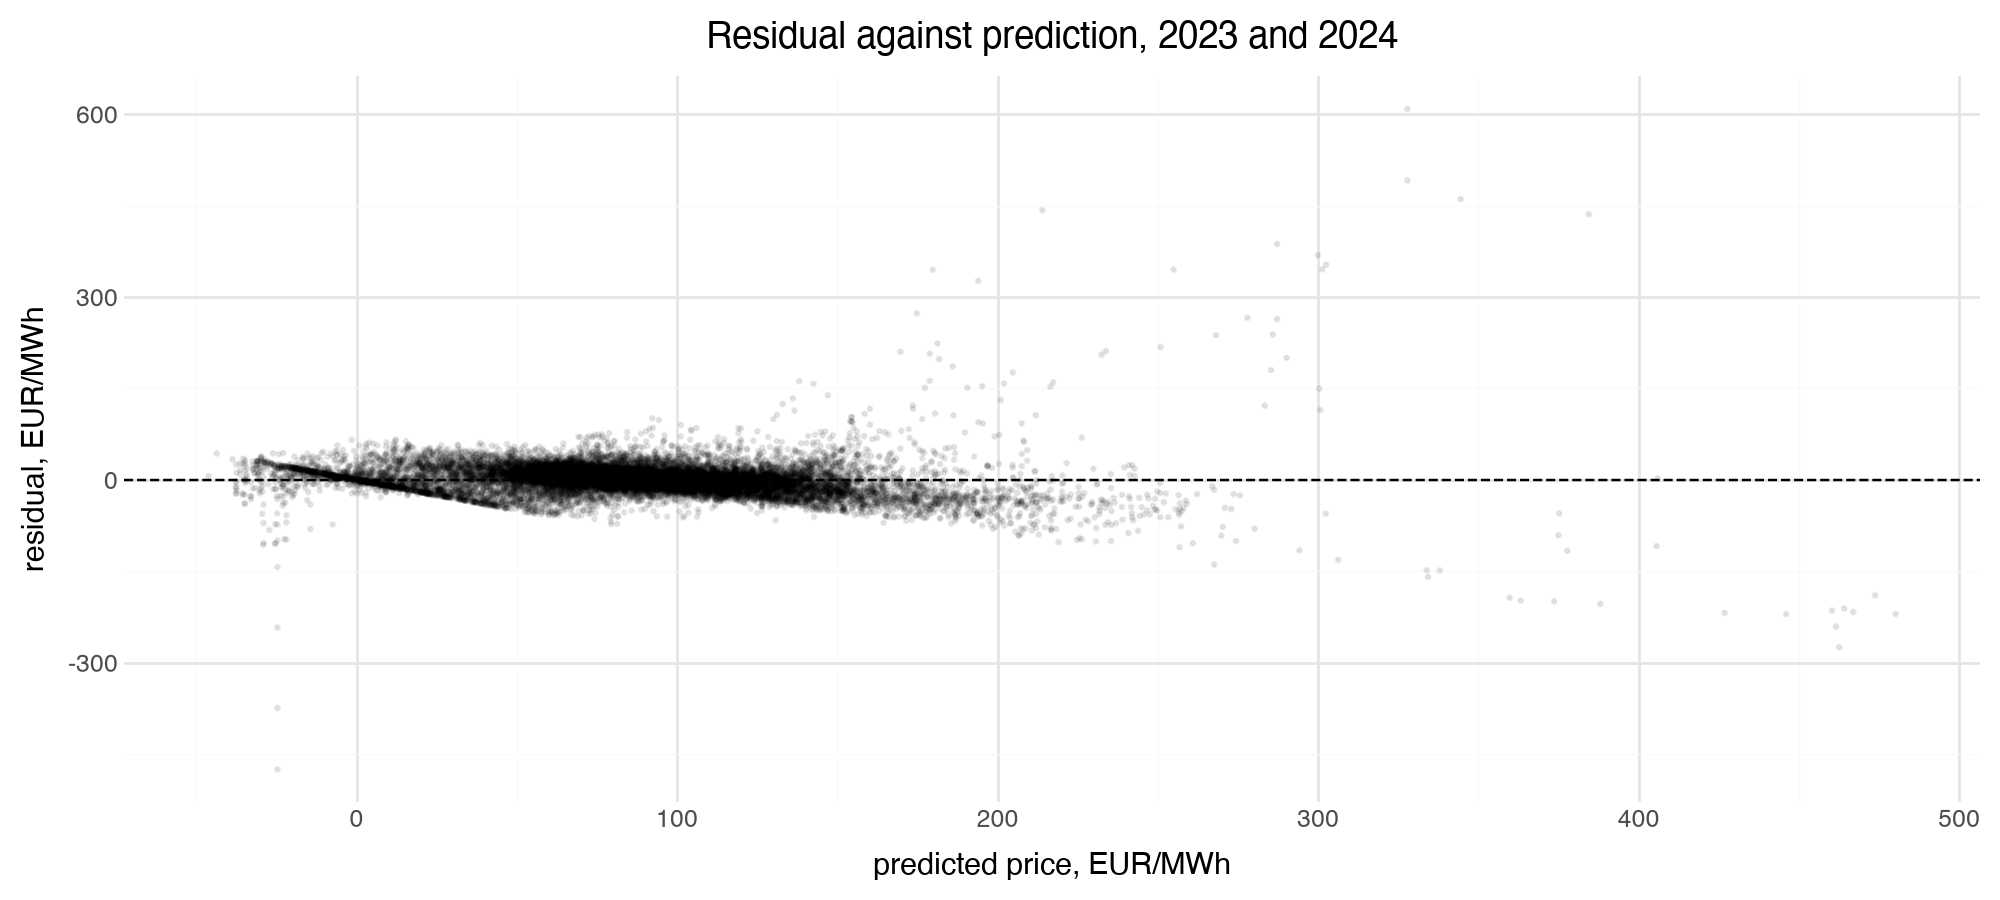

In [46]:
(
    ggplot(oof, aes("pred", "residual"))
    + geom_point(alpha=0.08, size=0.4)
    + geom_hline(yintercept=0, linetype="dashed")
    + labs(
        x="predicted price, EUR/MWh",
        y="residual, EUR/MWh",
        title="Residual against prediction, 2023 and 2024",
    )
)

The error spreads out as the prediction rises: mostly within ±50 EUR/MWh below a prediction of 150, and from about -270 to +610 above 300, where the model both misses spikes and overshoots. The diagonal edge at low predictions is hours that cleared near 0 EUR/MWh while the model expected up to 50.


Plot the mean residual per hour of day, with the band holding the middle 80% of residuals.


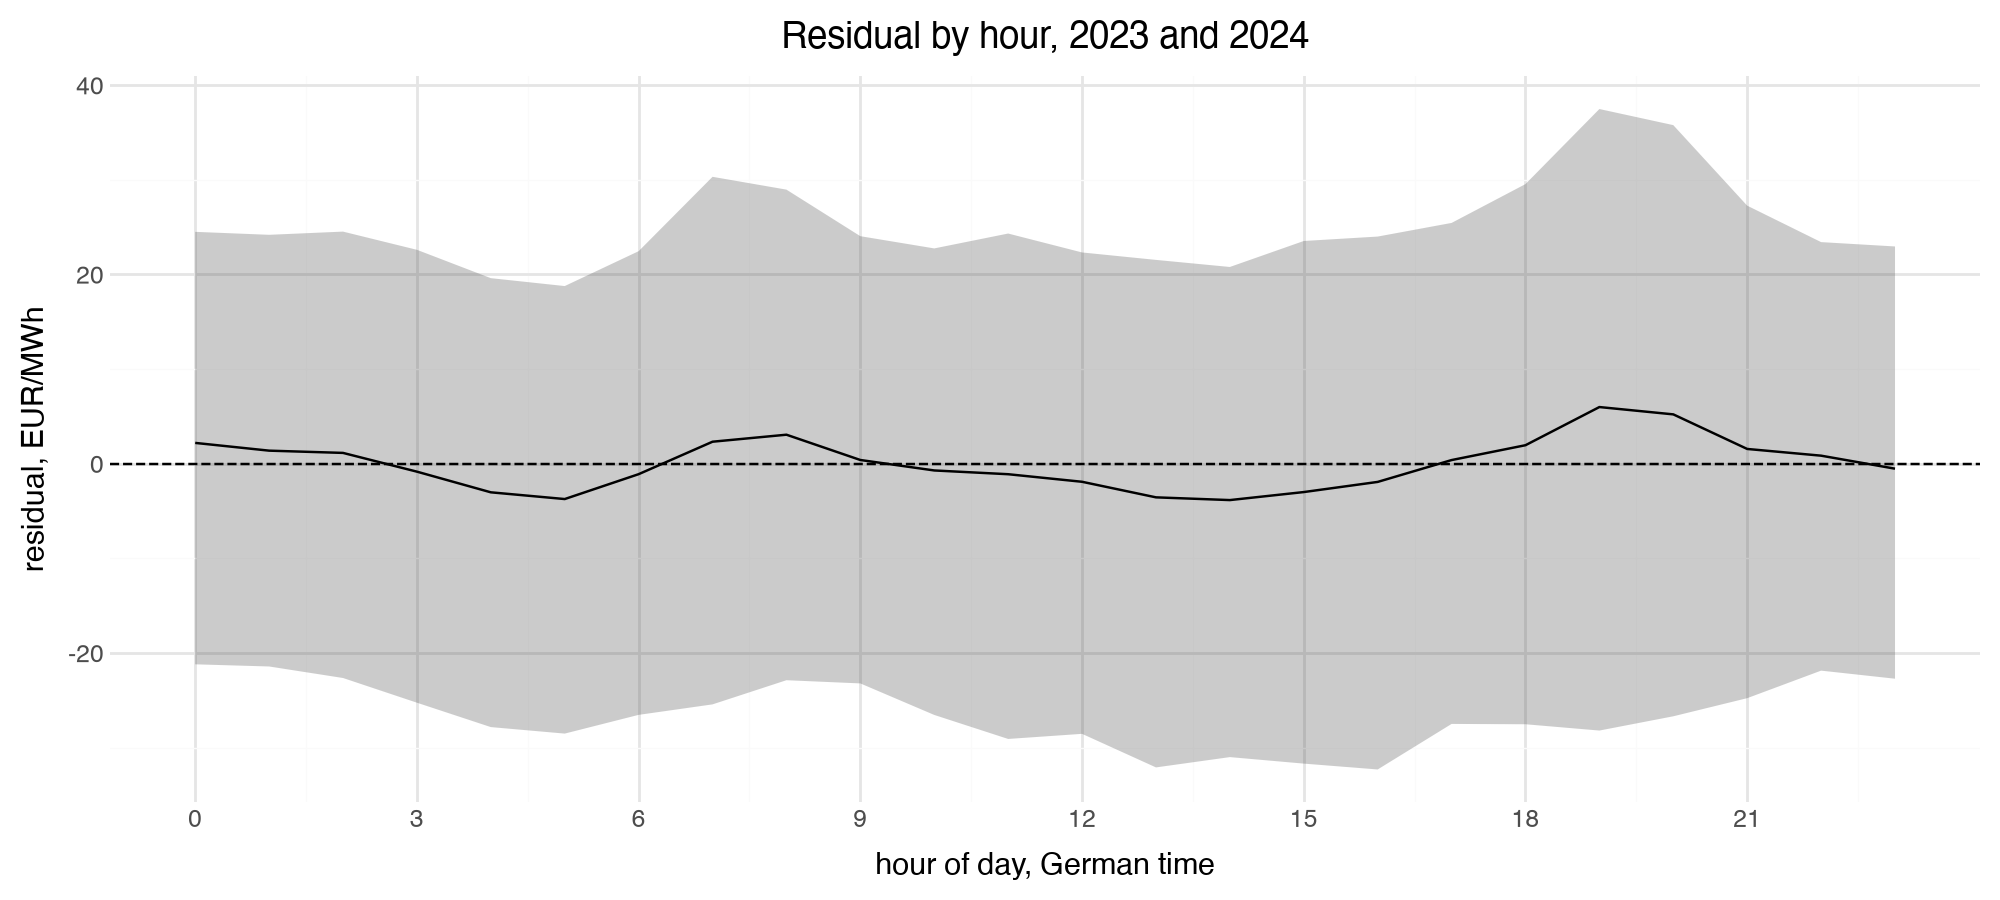

In [47]:
by_hour = oof.group_by("hour").agg(
    mean=pl.col("residual").mean(),
    low=pl.col("residual").quantile(0.1),
    high=pl.col("residual").quantile(0.9),
)

(
    ggplot(by_hour, aes("hour"))
    + geom_ribbon(aes(ymin="low", ymax="high"), alpha=0.25)
    + geom_line(aes(y="mean"))
    + geom_hline(yintercept=0, linetype="dashed")
    + scale_x_continuous(breaks=range(0, 24, 3))
    + labs(
        x="hour of day, German time",
        y="residual, EUR/MWh",
        title="Residual by hour, 2023 and 2024",
    )
)

The day's shape is close but not flat: the mean residual runs from -4 to +6 EUR/MWh, so the model predicts the evening peak at 19:00 to 20:00 too low and the early morning and early afternoon slightly too high. The middle 80% of residuals spans about ±25 EUR/MWh, widening to +38 at the evening peak.


Plot each day's mean residual over time.


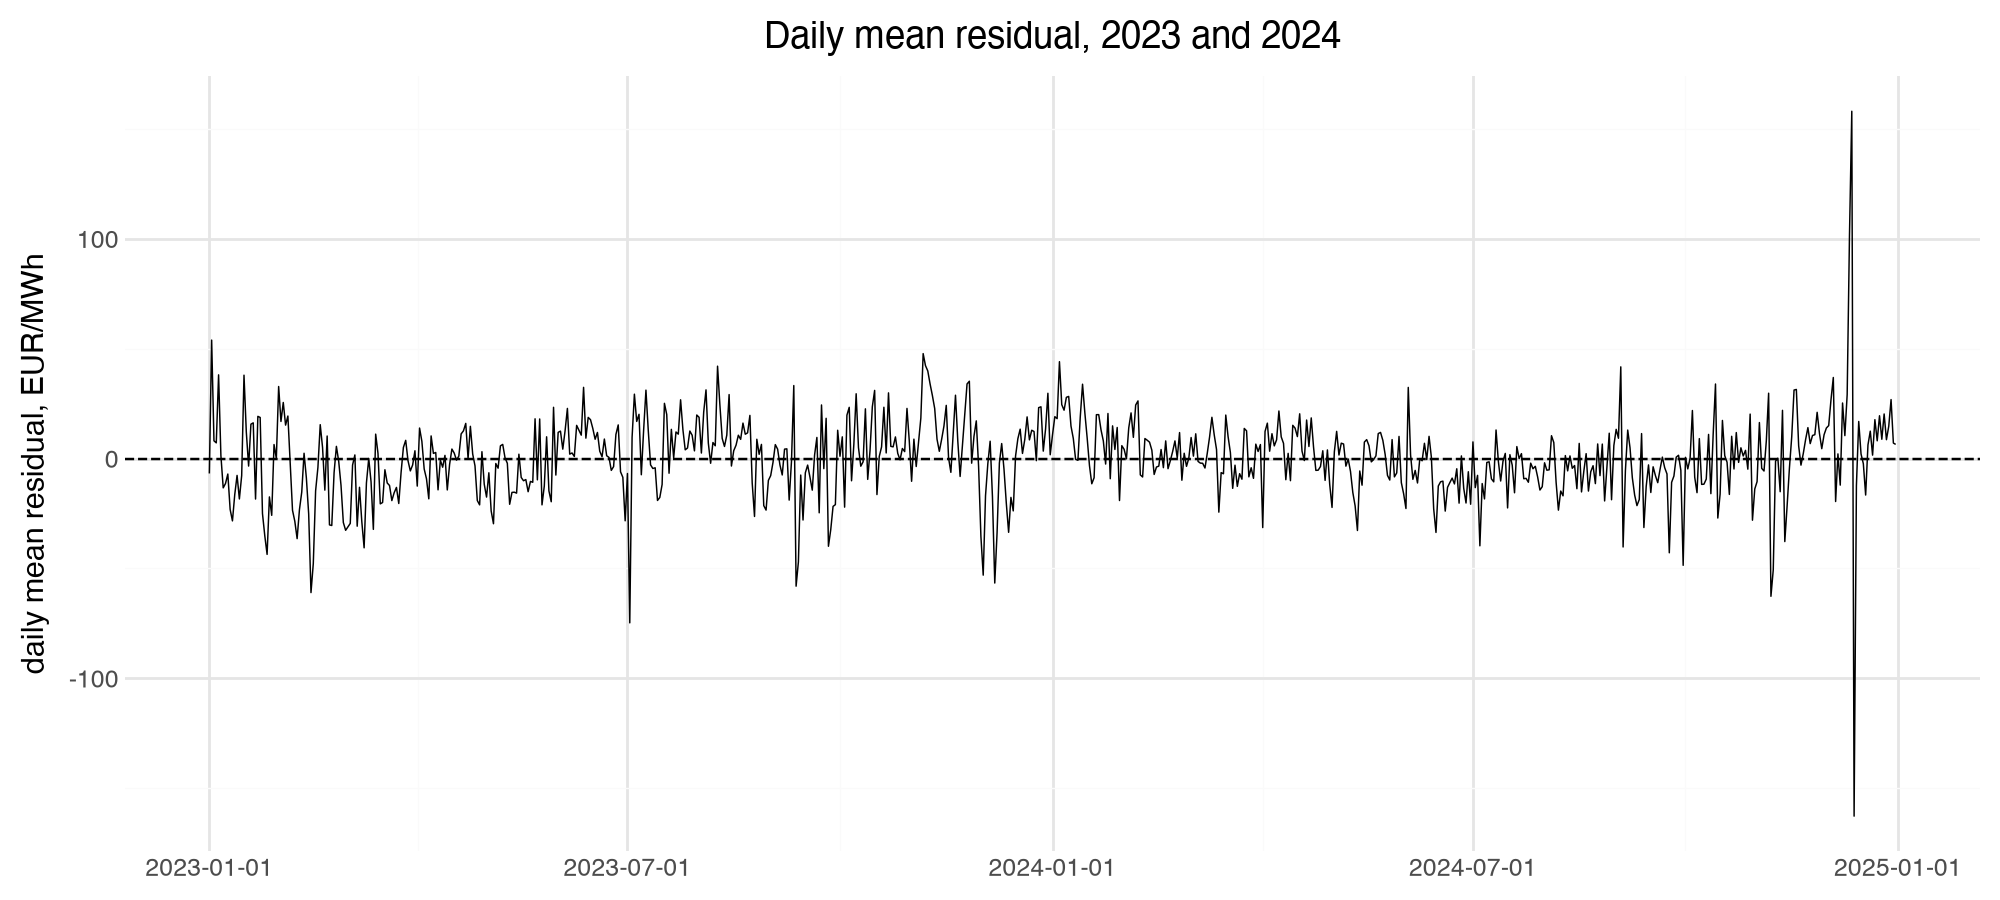

In [48]:
daily_residual = (
    oof.group_by("date").agg(residual=pl.col("residual").mean()).sort("date")
)

(
    ggplot(daily_residual, aes("date", "residual"))
    + geom_line(size=0.3)
    + geom_hline(yintercept=0, linetype="dashed")
    + labs(
        x="",
        y="daily mean residual, EUR/MWh",
        title="Daily mean residual, 2023 and 2024",
    )
)

Daily errors mostly stay within ±40 EUR/MWh with short streaks. The biggest misses come in December 2024, about +160 and then -165 EUR/MWh on consecutive days during a short windless cold spell, and about -75 at the start of July 2023.


Split the error by price band: negative hours, ordinary hours, and hours above 200 EUR/MWh.


In [49]:
oof.with_columns(
    band=pl.when(pl.col("price_da") < 0)
    .then(pl.lit("below-0"))
    .when(pl.col("price_da") > 200)
    .then(pl.lit("above-200"))
    .otherwise(pl.lit("0-to-200"))
).group_by("band").agg(
    hours=pl.len(),
    mae=pl.col("residual").abs().mean(),
    mean_residual=pl.col("residual").mean(),
).sort("mae")

band,hours,mae,mean_residual
str,u32,f64,f64
"""0-to-200""",16545,15.932,-0.607
"""below-0""",758,16.459,-5.047
"""above-200""",241,89.103,60.984


Ordinary and negative hours are both missed by 16 EUR/MWh, but the 241 hours above 200 EUR/MWh by 89, and they are predicted 61 too low on average. Misses this size weigh far more in RMSE than in MAE: the final model has an RMSE of 26.5 EUR/MWh against an MAE of 17.0.

One finding maps to a fix in the diagnostics table: errors that grow with the price level point to an asinh target. The evening peak predicted too low would point to deeper trees, but deeper settings did no better for XGBoost alone in section 5.3, so it stays a known weakness, with the spikes.


Test the asinh target against the final model on the same folds. On Lasso-then-XGBoost, the final model before section 5.3's check, the asinh target lowered the saving share from 96.0% to 92.4% and raised MAE from 16.1 to 18.7 EUR/MWh.


In [50]:
asinh_model = AsinhTarget(XGBRegressor(random_state=0, **FINAL_SETTINGS))
asinh_cv, _ = cross_validate(asinh_model, FINAL_COLUMNS, dev, FOLDS)

pl.DataFrame(
    [{"version": "final-model"} | final_cv, {"version": "asinh-target"} | asinh_cv]
).select(
    "version",
    "saving_share",
    "saving_share_fold_sd",
    "right_shift_share",
    "mae",
    "rmse",
    "mase",
)

version,saving_share,saving_share_fold_sd,right_shift_share,mae,rmse,mase
str,f64,f64,f64,f64,f64,f64
"""final-model""",0.956,0.012,0.722,16.961,26.546,0.617
"""asinh-target""",0.931,0.016,0.689,18.005,27.944,0.655


Tried, worse: the asinh target lowers the saving share from 95.6% to 93.1% and raises MAE from 17.0 to 18.0 EUR/MWh, as it did for the earlier models. Compressing the spikes also compresses the gaps between hours that pick the shift. The final model stays as it is.


## 7. Evaluation

### 7.1 Test: 2025

The final model is refitted on all development data, 2019-01-31 to 2024-12-31, and scored on 2025 beside the no-model references from section 5.1, which the result is measured against. No other model touches 2025: a held-out score must never drive a choice, so only the chosen model is scored. Earlier drafts of this notebook broke that rule and scored LEAR and three superseded final models on 2025; those runs changed no decision, and their results are not shown. The references that need a history use 2024: the training mean and last year's profile. `saving_eur_per_year` is what the picked shift saves against the standard 06:00 shift for 500 MWh a day, over a year.


Refit the final model, predict 2025, and score it beside the no-model references.


In [51]:
_ = final_model.fit(df_to_np(dev, FINAL_COLUMNS), dev["price_da"].to_numpy())
test_frame = test_2025.with_columns(
    pred=pl.Series(final_model.predict(df_to_np(test_2025, FINAL_COLUMNS)))
)

profile_2024 = (
    dev.filter(pl.col("year") == TEST_FROM - 1)
    .group_by("hour")
    .agg(profile=pl.col("price_da").mean())
)
test_frame = test_frame.join(profile_2024, on="hour", how="left").sort("utc_timestamp")
standard_2025 = np.where(test_frame["hour"].is_between(6, 13).to_numpy(), 0.0, 1.0)

pl.DataFrame(
    [
        {"method": "xgboost-final"}
        | evaluate(test_frame, test_frame["pred"].to_numpy()),
        {"method": "residual-load-rule"}
        | evaluate(
            test_frame,
            test_frame["fc_residual"].to_numpy(),
            pick_with_premium=False,
            report_error=False,
        ),
        {"method": "same-hour-yesterday"}
        | evaluate(test_frame, test_frame["price_lag24"].to_numpy()),
        {"method": "last-year-profile"}
        | evaluate(test_frame, test_frame["profile"].to_numpy(), report_error=False),
        {"method": "standard-shift"}
        | evaluate(
            test_frame, standard_2025, pick_with_premium=False, report_error=False
        ),
        {"method": "training-mean"}
        | evaluate(test_frame, np.full(test_frame.height, dev["price_da"].mean())),
    ]
).select(
    "method",
    "saving_share",
    "saving_eur_per_year",
    "shift_cost",
    "right_shift_share",
    "mae",
    "rmse",
    "mase",
)

method,saving_share,saving_eur_per_year,shift_cost,right_shift_share,mae,rmse,mase
str,f64,f64,f64,f64,f64,f64,f64
"""xgboost-final""",0.964,4309336.406,59.722,0.715,16.404,25.149,0.632
"""residual-load-rule""",0.941,4204679.688,60.296,0.707,null,null,null
"""same-hour-yesterday""",0.832,3716954.375,62.968,0.499,25.965,40.446,1.000
"""last-year-profile""",0.683,3054707.187,66.597,0.329,null,null,null
"""standard-shift""",0.000,0.000,83.335,0.014,null,null,null
"""training-mean""",-0.336,-1502665.312,91.569,0.066,35.753,52.563,1.377


On 2025 the model gets 96.4% of the possible saving, against 94.1% for the residual-load rule and 83.2% for same hour yesterday. Against the standard 06:00 shift it saves 4.31 million EUR a year, 105,000 EUR more than the rule, and it picks the cheapest shift on 71.5% of days, with an MAE of 16.4 EUR/MWh.

The test matches the folds: in CV the model led the rule by 1.5 percentage points (95.6% against 94.1%), just beyond its fold SD of 1.2, and here by 2.3 points, so the lead holds on a year neither the model nor the exploration saw.


### 7.2 What the test shows

Ranked by how much each matters for the decision:

1. The forecast beats the residual-load rule: by 1.5 percentage points in CV, just beyond its fold SD of 1.2, and by 2.3 points on 2025, about 105,000 EUR a year for this plant.
2. That gain is small next to the decision itself. Choosing the shift at all, even by the residual-load rule, is worth 4.2 million EUR a year against a fixed 06:00 shift, about 40 times the model's extra 105,000.
3. LEAR, the field's standard linear model for day-ahead prices, gets 93.5% of the possible saving on the folds against the final model's 95.6%, a gap beyond the noise, so the final model holds up against the method the field measures itself by.
4. Price memory is the feature group that matters. Neither the Lasso stage nor the neighbour spreads is shown to earn its place under the rules, so the simpler model goes forward, and both random searches found flat tops, so the exact settings matter little.
5. Spikes are the weak point: hours above 200 EUR/MWh are missed by 89 EUR/MWh in CV, and the evening peak is predicted a few EUR/MWh too low. The asinh target made the decision worse.

#### To keep in mind going forward

1. The reserve, 2026-01-01 to 2026-10-11, has not been scored. Only the final model is scored on it, once, as a bonus, with nothing changed after it.
2. The edge over the residual-load rule rests on two validation years and one test year, and the fold SD comes from only two folds, so "inside the noise" is a rough call throughout.


### 7.3 Reserve: 2026, a bonus score

The final model, refitted with the same settings on everything before the reserve (2019-01-31 to 2025-12-31), scores 2026-01-01 to 2026-10-11 once, beside three references. Nine months miss the winter peaks of a full year, so this is a bonus check; the 2025 test stays the result, and nothing changes after it.


Refit the final model on all data before 2026, predict the reserve, and score it beside the references.


In [52]:
before_reserve = pl.concat([dev, test_2025])
reserve_model = XGBRegressor(random_state=0, **FINAL_SETTINGS)
_ = reserve_model.fit(
    df_to_np(before_reserve, FINAL_COLUMNS), before_reserve["price_da"].to_numpy()
)
reserve_frame = reserve_2026.with_columns(
    pred=pl.Series(reserve_model.predict(df_to_np(reserve_2026, FINAL_COLUMNS)))
)
standard_2026 = np.where(reserve_frame["hour"].is_between(6, 13).to_numpy(), 0.0, 1.0)

pl.DataFrame(
    [
        {"method": "xgboost-final"}
        | evaluate(reserve_frame, reserve_frame["pred"].to_numpy()),
        {"method": "residual-load-rule"}
        | evaluate(
            reserve_frame,
            reserve_frame["fc_residual"].to_numpy(),
            pick_with_premium=False,
            report_error=False,
        ),
        {"method": "same-hour-yesterday"}
        | evaluate(reserve_frame, reserve_frame["price_lag24"].to_numpy()),
        {"method": "standard-shift"}
        | evaluate(
            reserve_frame, standard_2026, pick_with_premium=False, report_error=False
        ),
    ]
).select(
    "method",
    "saving_share",
    "saving_eur_per_year",
    "shift_cost",
    "right_shift_share",
    "mae",
    "rmse",
    "mase",
)

method,saving_share,saving_eur_per_year,shift_cost,right_shift_share,mae,rmse,mase
str,f64,f64,f64,f64,f64,f64,f64
"""xgboost-final""",0.987,5649573.058,62.114,0.750,24.780,35.972,0.785
"""residual-load-rule""",0.978,5600420.956,62.383,0.736,null,null,null
"""same-hour-yesterday""",0.898,5140528.186,64.903,0.546,31.551,49.583,1.000
"""standard-shift""",0.000,0.000,93.070,0.000,null,null,null


On the reserve the model gets 98.7% of the possible saving against 97.8% for the residual-load rule, a lead of 0.9 points worth about 49,000 EUR a year, smaller than 2025's 2.3. Its MAE rises to 24.8 EUR/MWh and its MASE to 0.79, so the price is harder to forecast in 2026, yet every method lands closer to hindsight than in 2025: so far this year the cheapest shift is easier to spot, which leaves a forecast less to add.


## 8. In practice

What the final model means for the plant in 2025, the test year: where the year's saving comes from, and one day of the decision up close.

### 8.1 Savings through 2025

`saved_eur` is the running total, from 1 January, of what each way of choosing the shift saves against the standard 06:00 shift: each day's cost of the standard shift minus the cost of the chosen one, electricity plus premium, for 500 MWh. Hindsight, the cheapest shift each day, is the most any forecast could save.


Add up each day's cost of the standard, model, residual-load-rule and hindsight shifts, and plot the running saving.


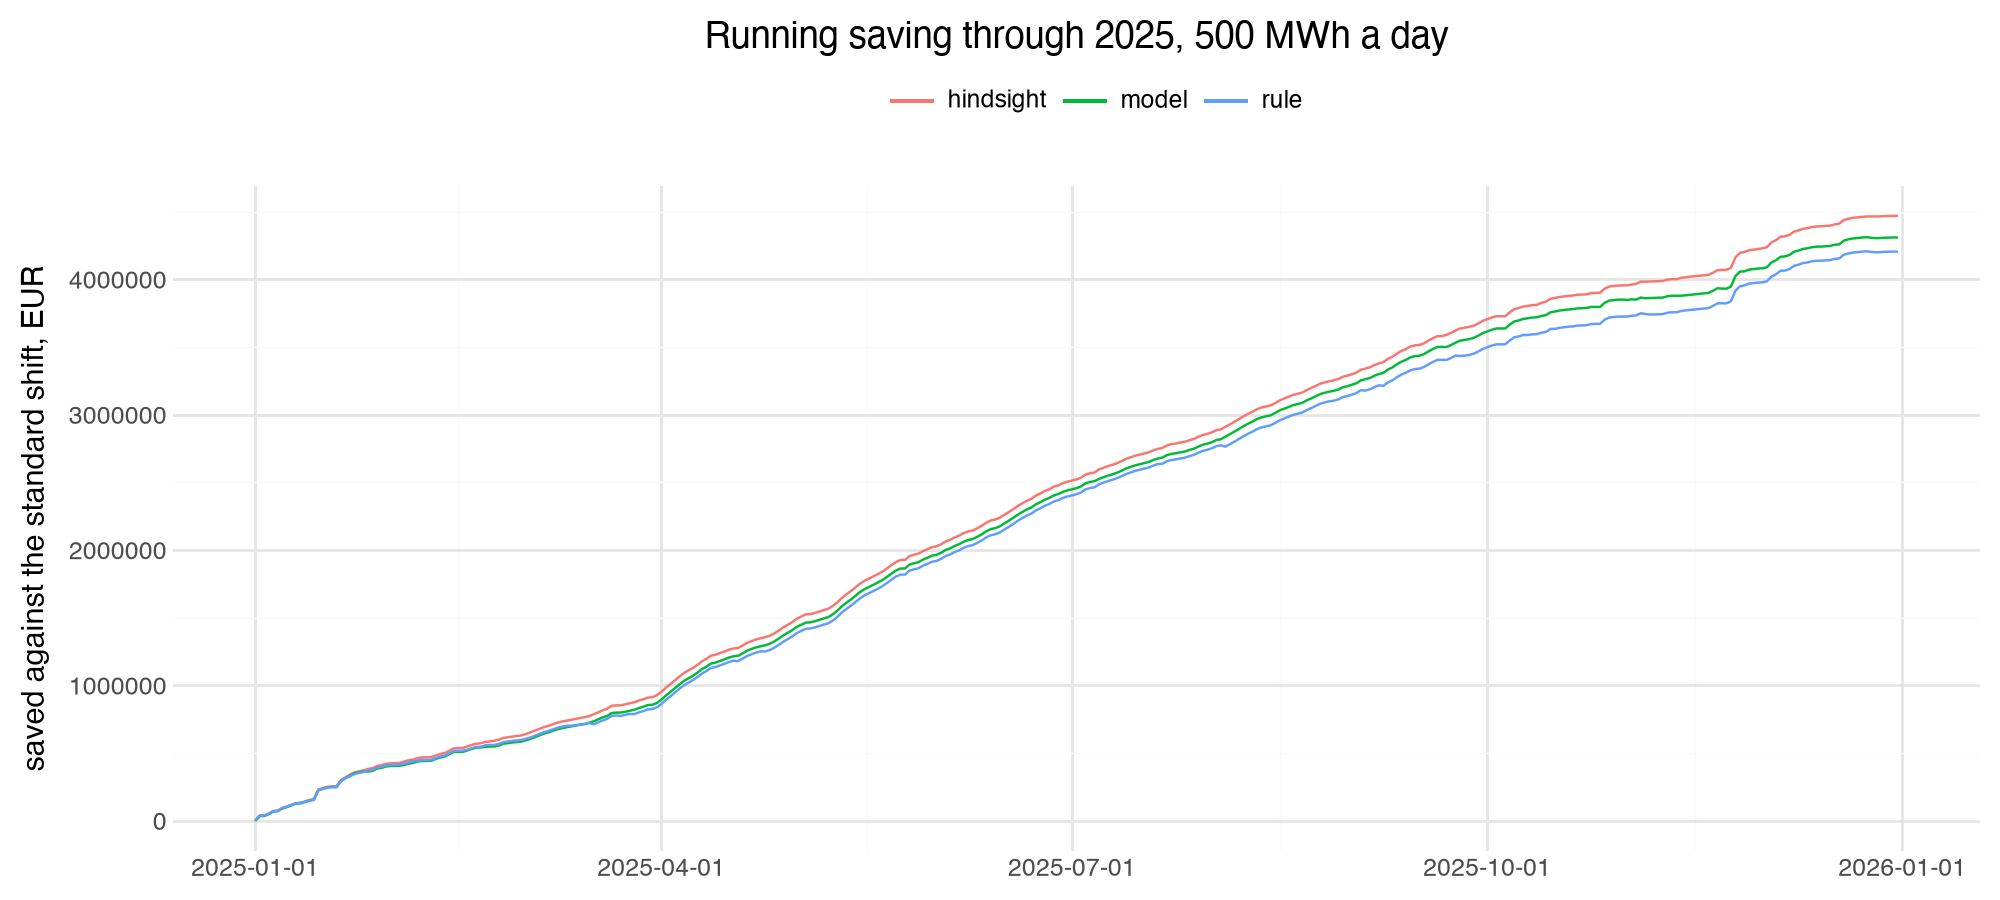

In [53]:
SHIFT_CHOICES = ["model", "rule", "hindsight"]
day_costs = (
    test_frame.with_columns(
        cost=(pl.col("price_da") + premium())
        * SHIFT_MW,  # EUR for that hour's 62.5 MWh
        standard=pl.col("hour").is_between(6, 13),
        model=best_shift(pl.col("pred") + premium()),
        rule=best_shift(pl.col("fc_residual")),
        hindsight=best_shift(pl.col("price_da") + premium()),
    )
    .group_by("date")
    .agg(
        [
            pl.col("cost").filter(pl.col(s)).sum().alias(s)
            for s in ["standard", *SHIFT_CHOICES]
        ]
    )
    .sort("date")
)
saved = day_costs.select(
    "date",
    *[(pl.col("standard") - pl.col(s)).cum_sum().alias(s) for s in SHIFT_CHOICES],
).unpivot(index="date", variable_name="shift_choice", value_name="saved_eur")

(
    ggplot(saved, aes("date", "saved_eur", color="shift_choice"))
    + geom_line()
    + labs(
        x="",
        y="saved against the standard shift, EUR",
        color="",
        title="Running saving through 2025, 500 MWh a day",
    )
)

By the end of 2025 the model has saved about 4.31 million EUR against the standard shift, the residual-load rule 4.20 million and hindsight 4.47 million. The model and the rule run level until March; from April the model pulls ahead and the gap keeps widening, so its value builds over many days rather than coming from one spell.


### 8.2 One day of the decision

The day shown is the 2025 weekday whose mean price is closest to the year's median day, so it is typical rather than picked for how the model did. The lines are the cost per MWh of each hour, price plus premium, as cleared and as forecast; the shaded bands are the model's chosen shift and the cheapest shift in hindsight.


Find the typical weekday, mark both shifts, and plot the forecast against the cleared price.


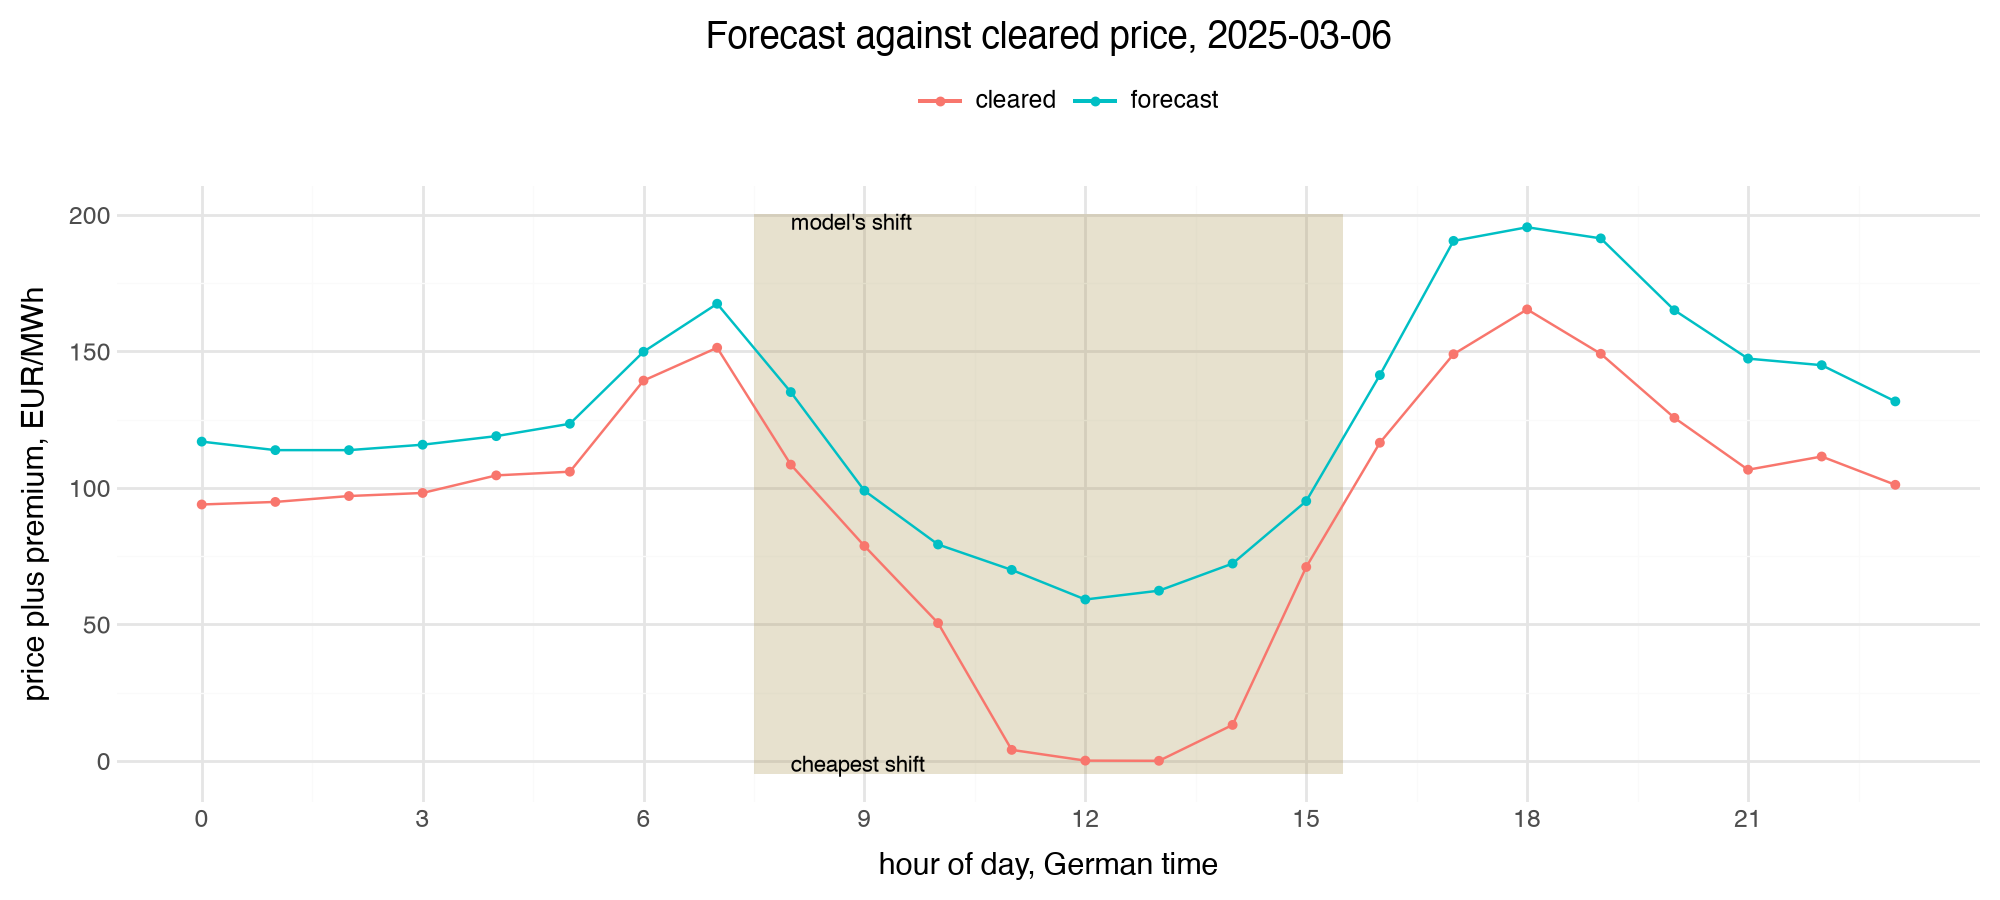

In [54]:
daily_mean = test_frame.group_by("date").agg(
    mean_price=pl.col("price_da").mean(), weekday=pl.col("weekday").first()
)
median_day = daily_mean["mean_price"].median()
example_date = (
    daily_mean.filter(pl.col("weekday") <= 5)
    .sort((pl.col("mean_price") - median_day).abs())
    .row(0, named=True)["date"]
)

day = test_frame.filter(pl.col("date") == example_date).with_columns(
    cleared=pl.col("price_da") + premium(),
    forecast=pl.col("pred") + premium(),
    model_shift=best_shift(pl.col("pred") + premium()),
    best_shift_hindsight=best_shift(pl.col("price_da") + premium()),
)
model_hours = day.filter(pl.col("model_shift"))["hour"].to_list()
best_hours = day.filter(pl.col("best_shift_hindsight"))["hour"].to_list()
lines = day.unpivot(
    index="hour",
    on=["cleared", "forecast"],
    variable_name="series",
    value_name="eur_per_mwh",
)
values = lines["eur_per_mwh"].to_list()
low, high = min(values) - 5, max(values) + 5

(
    ggplot(lines, aes("hour", "eur_per_mwh", color="series"))
    + annotate(
        "rect",
        xmin=min(model_hours) - 0.5,
        xmax=max(model_hours) + 0.5,
        ymin=low,
        ymax=high,
        fill="steelblue",
        alpha=0.15,
    )
    + annotate(
        "rect",
        xmin=min(best_hours) - 0.5,
        xmax=max(best_hours) + 0.5,
        ymin=low,
        ymax=high,
        fill="orange",
        alpha=0.15,
    )
    + annotate(
        "text", x=min(model_hours), y=high - 3, label="model's shift", ha="left", size=8
    )
    + annotate(
        "text", x=min(best_hours), y=low + 3, label="cheapest shift", ha="left", size=8
    )
    + geom_line()
    + geom_point(size=1)
    + scale_x_continuous(breaks=range(0, 24, 3))
    + labs(
        x="hour of day, German time",
        y="price plus premium, EUR/MWh",
        color="",
        title=f"Forecast against cleared price, {example_date}",
    )
)

On 2025-03-06 the model's shift, 08:00 to 16:00, is also the cheapest one. Its forecast runs 20 to 60 EUR/MWh too high in every hour and misses how deep the midday solar dip goes, but it gets the shape of the day right, which is all the decision uses.


## Conclusion

The forecast does the job the plant needs. On 2025, a full year it never saw, its chosen shifts capture 96.4% of the possible saving against a standard 06:00 shift: about 4.31 million EUR for 500 MWh a day, and 105,000 EUR a year more than choosing the shift by forecast residual load alone. The model is XGBoost on calendar, forecast and recent-price features, chosen over a two-stage Lasso-then-XGBoost and LEAR, the field's standard linear model, under rules fixed before each comparison. Most of the money comes from choosing the shift at all; the forecast's own share is the last 2.3 percentage points, a lead that sits just beyond the noise in cross-validation. The 2026 reserve points the same way, with a smaller lead of 0.9 points.

Limitations, ranked by how much they could change the answer:

1. The TSO forecasts used as inputs are published at 18:00 on D-1, after the 11:55 gate. A real buyer would use a vendor forecast made the same morning, so the results assume one of similar quality is bought; this exact source would not be available in time.
2. The evidence rests on two validation years and one test year, and each fold SD on just two numbers, so the gap to the residual-load rule is a narrow call.
3. Spikes are missed: hours above 200 EUR/MWh by about 89 EUR/MWh in CV, and the evening peak is predicted a few EUR/MWh too low.
4. The decision is simplified: a shift stays within one day, the night and weekend premiums do not stack, and the plant is treated as a price taker, which `project.md` puts at about 0.18 EUR/MWh of price impact.
5. No fuel price and no public holidays are in the data, so the level comes from recent prices alone.
6. LEAR was refitted once a year rather than daily as published, which likely understates it.
